# Download dependencies & data

In [ ]:
!pip install torch-geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 9.5 MB/s  0:00:00


In [ ]:
!pip install -q graphviz

# Install Graphviz renderer if not already installed
!apt-get install -y -qq graphviz

In [ ]:
!pip install --no-deps --no-index pyg_lib -f "https://data.pyg.org/whl/torch-2.14.0+cu130.html"

# After that, restart kernel, then run the subsequent code to check the dependencies

Looking in links: https://data.pyg.org/whl/torch-2.14.0+cu130.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 70.4 MB/s  0:00:00


In [ ]:
import torch
import torch_geometric
import pyg_lib
import numpy as np
import pandas as pd
import math
import subprocess
import joblib
import copy
import lightgbm as lgb
import sys
import platform

from torch_geometric.typing import WITH_PYG_LIB
from torch_geometric.nn import HeteroConv, SAGEConv
from torch_geometric.loader import NeighborLoader
from torch_geometric.data import HeteroData
from collections import OrderedDict
from torch import nn
from torch.nn import functional as F
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)
from graphviz import Digraph
from IPython.display import display, SVG
from pathlib import Path
from datetime import datetime
from __future__ import annotations
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report

In [332]:
print("Python:", sys.version)
print("OS:", platform.system())
print("Architecture:", platform.machine())
print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("PyG:", torch_geometric.__version__)
print("pyg-lib:", pyg_lib.__version__)
print("PyG backend available:", WITH_PYG_LIB)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
OS: Linux
Architecture: x86_64
PyTorch: 2.14.1+cu130
CUDA version: 13.0
CUDA available: True
PyG: 2.8.1
pyg-lib: 0.9.0+pt214cu130
PyG backend available: True


In [ ]:
!git clone --depth 1 https://github.com/nycubigdata-2026fall/BigData2026-Assignment2.git assignment2

Cloning into 'assignment2'...
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 11 (delta 1), reused 11 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (11/11), 135.25 KiB | 5.88 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-11-{01..11}-{0..23}.json.gz

--2026-11-13 11:56:37--  https://data.gharchive.org/2026-11-01-0.json.gz
Resolving data.gharchive.org (data.gharchive.org)... 188.114.97.0, 188.114.96.0, 2a06:98c1:3120::, ...
Connecting to data.gharchive.org (data.gharchive.org)|188.114.97.0|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6240448 (6.0M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-11-01-0.json.gz’

2026-11-01-0.json.g 100%[===================>]   5.95M  --.-KB/s    in 0.05s   

2026-11-13 11:56:37 (121 MB/s) - ‘RAW_DATA_FOLDER/2026-11-01-0.json.gz’ saved [6240448/6240448]

--2026-11-13 11:56:37--  https://data.gharchive.org/2026-11-01-1.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 6320143 (6.0M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-11-01-1.json.gz’

2026-11-01-1.json.g 100%[===================>]   6.03M  --.-KB/s    in 0.04s   

2026-11-13 11:56:37 (168 MB/s) - ‘RAW_DATA_FOLDER/2026-11-01-1.json.gz’

In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-10-{01..31}-{0..23}.json.gz

In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-09-{01..30}-{0..23}.json.gz

Streaming output truncated to the last 5000 lines.
Length: 16579167 (16M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-09-10-4.json.gz’

2026-09-10-4.json.g 100%[===================>]  15.81M  --.-KB/s    in 0.09s   

2026-11-13 12:03:04 (170 MB/s) - ‘RAW_DATA_FOLDER/2026-09-10-4.json.gz’ saved [16579167/16579167]

--2026-11-13 12:03:04--  https://data.gharchive.org/2026-09-10-5.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 15661212 (15M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-09-10-5.json.gz’

2026-09-10-5.json.g 100%[===================>]  14.94M  --.-KB/s    in 0.07s   

2026-11-13 12:03:04 (200 MB/s) - ‘RAW_DATA_FOLDER/2026-09-10-5.json.gz’ saved [15661212/15661212]

--2026-11-13 12:03:04--  https://data.gharchive.org/2026-09-10-6.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 15480731 (15M) [application/gzip]
Saving to: 

In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-08-{01..31}-{0..23}.json.gz

Streaming output truncated to the last 5000 lines.
Length: 21278231 (20M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-08-11-4.json.gz’

2026-08-11-4.json.g 100%[===================>]  20.29M  --.-KB/s    in 0.1s    

2026-11-13 12:07:25 (140 MB/s) - ‘RAW_DATA_FOLDER/2026-08-11-4.json.gz’ saved [21278231/21278231]

--2026-11-13 12:07:25--  https://data.gharchive.org/2026-08-11-5.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 21181147 (20M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-08-11-5.json.gz’

2026-08-11-5.json.g 100%[===================>]  20.20M  --.-KB/s    in 0.09s   

2026-11-13 12:07:25 (214 MB/s) - ‘RAW_DATA_FOLDER/2026-08-11-5.json.gz’ saved [21181147/21181147]

--2026-11-13 12:07:25--  https://data.gharchive.org/2026-08-11-6.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 21317291 (20M) [application/gzip]
Saving to: 

In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-07-{01..31}-{0..23}.json.gz

Streaming output truncated to the last 5000 lines.
Length: 21232946 (20M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-07-11-4.json.gz’

2026-07-11-4.json.g 100%[===================>]  20.25M  --.-KB/s    in 0.1s    

2026-11-13 12:10:40 (183 MB/s) - ‘RAW_DATA_FOLDER/2026-07-11-4.json.gz’ saved [21232946/21232946]

--2026-11-13 12:10:40--  https://data.gharchive.org/2026-07-11-5.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 21075078 (20M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-07-11-5.json.gz’

2026-07-11-5.json.g 100%[===================>]  20.10M   118MB/s    in 0.2s    

2026-11-13 12:10:41 (118 MB/s) - ‘RAW_DATA_FOLDER/2026-07-11-5.json.gz’ saved [21075078/21075078]

--2026-11-13 12:10:41--  https://data.gharchive.org/2026-07-11-6.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 20991408 (20M) [application/gzip]
Saving to: 

In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-06-{01..30}-{0..23}.json.gz

Streaming output truncated to the last 5000 lines.
Length: 23390055 (22M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-06-10-4.json.gz’

2026-06-10-4.json.g 100%[===================>]  22.31M  7.69MB/s    in 2.9s    

2026-11-13 12:14:33 (7.69 MB/s) - ‘RAW_DATA_FOLDER/2026-06-10-4.json.gz’ saved [23390055/23390055]

--2026-11-13 12:14:33--  https://data.gharchive.org/2026-06-10-5.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 24762880 (24M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-06-10-5.json.gz’

2026-06-10-5.json.g 100%[===================>]  23.62M   118MB/s    in 0.2s    

2026-11-13 12:14:33 (118 MB/s) - ‘RAW_DATA_FOLDER/2026-06-10-5.json.gz’ saved [24762880/24762880]

--2026-11-13 12:14:33--  https://data.gharchive.org/2026-06-10-6.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 22555504 (22M) [application/gzip]
Saving to:

In [ ]:
!python /content/assignment2/scripts/preprocess.py --raw /content/RAW_DATA_FOLDER --out /content/assignment2/data/

Step 1: 3936 GH Archive hour files, 2026-06-01-0 to 2026-11-11-23 (UTC).
Step 2: keeping the cohort users' events.
  24/3936 hours read
  48/3936 hours read
  72/3936 hours read
  96/3936 hours read
  120/3936 hours read
  144/3936 hours read
  168/3936 hours read
  192/3936 hours read
  216/3936 hours read
  240/3936 hours read
  264/3936 hours read
  288/3936 hours read
  312/3936 hours read
  336/3936 hours read
  360/3936 hours read
  384/3936 hours read
  408/3936 hours read
  432/3936 hours read
  456/3936 hours read
  480/3936 hours read
  504/3936 hours read
  528/3936 hours read
  552/3936 hours read
  576/3936 hours read
  600/3936 hours read
  624/3936 hours read
  648/3936 hours read
  672/3936 hours read
  696/3936 hours read
  720/3936 hours read
  744/3936 hours read
  768/3936 hours read
  792/3936 hours read
  816/3936 hours read
  840/3936 hours read
  864/3936 hours read
  888/3936 hours read
  912/3936 hours read
  936/3936 hours read
  960/3936 hours read
  984/393

In [ ]:
# !unzip /content/data_jun_nov.zip -d /


Archive:  /content/data_jun_nov.zip
   creating: /content/assignment2/data/
   creating: /content/assignment2/data/db/
  inflating: /content/assignment2/data/db/Pushes.parquet  
  inflating: /content/assignment2/data/db/Issues.parquet  
  inflating: /content/assignment2/data/db/IssueComments.parquet  
  inflating: /content/assignment2/data/db/Repositories.parquet  
  inflating: /content/assignment2/data/db/PRReviewComments.parquet  
  inflating: /content/assignment2/data/db/PullRequests.parquet  
  inflating: /content/assignment2/data/db/Users.parquet  
  inflating: /content/assignment2/data/db/PRReviews.parquet  


# Step 1

In [ ]:
# Load dataset

DATA = "assignment2/data/db"

users = pd.read_parquet(f"{DATA}/Users.parquet")
repos = pd.read_parquet(f"{DATA}/Repositories.parquet")
prs = pd.read_parquet(f"{DATA}/PullRequests.parquet")
issues = pd.read_parquet(f"{DATA}/Issues.parquet")
issue_comments = pd.read_parquet(f"{DATA}/IssueComments.parquet")
reviews = pd.read_parquet(f"{DATA}/PRReviews.parquet")
review_comments = pd.read_parquet(f"{DATA}/PRReviewComments.parquet")
pushes = pd.read_parquet(f"{DATA}/Pushes.parquet")

In [ ]:
# Build tabels registry
tables = {
    "users": users,
    "repos": repos,
    "prs": prs,
    "issues": issues,
    "issue_comments": issue_comments,
    "reviews": reviews,
    "review_comments": review_comments,
    "pushes": pushes
}

for name, df in tables.items():
    print(f"\n{'='*60}")
    print(name.upper())
    print(f"shape: {df.shape}")
    print(df.dtypes)


USERS
shape: (14834, 6)
user_id                    int64
github_user_id             Int64
login                     object
is_bot                   boolean
is_cohort                boolean
first_seen_at     datetime64[ns]
dtype: object

REPOS
shape: (48563, 7)
repo_id                    int64
github_repo_id             Int64
name                      object
owner_login               object
org_id                     Int64
org_login                 object
first_seen_at     datetime64[ns]
dtype: object

PRS
shape: (60262, 18)
pr_id                     int64
github_pr_id              Int64
repo_id                   Int64
number                    Int64
author_id                 Int64
title                    object
draft                   boolean
head_ref                 object
base_ref                 object
head_sha                 object
base_sha                 object
head_repo_id              Int64
is_cross_repo           boolean
created_at       datetime64[ns]
merged_at        date

In [ ]:
# Isolate the cohort users

# Only cohort users receive target labels.
# Non-cohort users can still appear as graph context.
cohort_users = users[users["is_cohort"]==True].copy()


print("All users:", len(users))
print("Cohort users:", len(cohort_users))

All users: 14834
Cohort users: 7745


In [ ]:
# Convert date columns to datetime.dtype
time_columns = {
    "users": ["first_seen_at"],
    "repos": ["first_seen_at"],
    "prs": [
        "created_at",
        "merged_at",
        "closed_at",
        "first_seen_at",
    ],
    "issues": [
        "created_at",
        "closed_at",
        "first_seen_at",
    ],
    "issue_comments": ["created_at"],
    "reviews": [
        "submitted_at",
        "dismissed_at",
        "first_seen_at",
    ],
    "review_comments": ["created_at"],
    "pushes": ["created_at"],
}

for table_name, cols in time_columns.items():
    df = tables[table_name]

    for col in cols:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col])

In [ ]:
print(cohort_users.head())

print("\nPull Requests:")
print(prs.head())

print("\nIssues:")
print(issues.head())

print("\nPushes:")
print(pushes.head())

   user_id   github_user_id             login  is_bot  is_cohort  \
0        0  773153677503676  39c6daa6dd957bd8   False       True   
1        1  191680090512864  036853e375d0da2b   False       True   
2        2  434124789218581  9b3c7fbab4361ade   False       True   
3        3  877784714956504  786636440110cad3   False       True   
4        4  726067014227275  c37f70789bb85453   False       True   

        first_seen_at  
0 2026-06-01 00:00:03  
1 2026-06-01 00:00:04  
2 2026-06-01 00:00:11  
3 2026-06-01 00:00:24  
4 2026-06-01 00:00:24  

Pull Requests:
   pr_id     github_pr_id  repo_id  number  author_id title  draft  \
0      0  815482431038859        6      16       <NA>  None   <NA>   
1      1  222980994825546       15      32       <NA>  None   <NA>   
2      2  564329603090639       22       7         22  None   <NA>   
3      3  808072935366568       35     180       <NA>  None   <NA>   
4      4  724763039218346       41      35       <NA>  None   <NA>   

          

In [ ]:
# Check for missing user IDs
check_cols = {
    "prs.author_id": prs["author_id"],
    "issues.author_id": issues["author_id"],
    "issue_comments.author_id": issue_comments["author_id"],
    "reviews.reviewer_id": reviews["reviewer_id"],
    "review_comments.author_id": review_comments["author_id"],
    "pushes.user_id": pushes["user_id"],
}

for name, s in check_cols.items():
    print(
        name,
        "missing:",
        s.isna().sum(),
        "/",
        len(s)
    )

prs.author_id missing: 36380 / 60262
issues.author_id missing: 0 / 38320
issue_comments.author_id missing: 0 / 20329
reviews.reviewer_id missing: 0 / 16387
review_comments.author_id missing: 0 / 12061
pushes.user_id missing: 0 / 478598


# Step 3

In [ ]:
# =========================== RUN CONFIGURATION ==============================
# IMPORTANT: Select ONE workflow and rerun from Step 3 through the model cells.
# Use "benchmark" for the Sep 27 TA-reference week; "final" for longer training
# and the official Nov 22 test week. Never compare results across modes as if
# training/evaluation data were identical.
RUN_MODE = "final"  # change to "benchmark" to reproduce the September evaluation
assert RUN_MODE in {"benchmark", "final"}


def taiwan_midnight_to_utc_naive(date_string):
    """Convert a Taiwan-local calendar date midnight into UTC-naive Parquet time."""
    return (
        pd.Timestamp(date_string, tz="Asia/Taipei")
        .tz_convert("UTC")
        .tz_localize(None)
    )

if RUN_MODE == "benchmark":
    # 5 training weeks: Aug 16–Sep 13; 1 tuning week: Sep 20;
    # held-out test/benchmark week: Sep 27–Oct 4 (Taiwan time).
    prediction_times_tw = pd.date_range(
        start="2026-08-16", end="2026-09-27",
        freq="7D", tz="Asia/Taipei"
    )
    tuning_t = taiwan_midnight_to_utc_naive("2026-09-20")
    benchmark_t = taiwan_midnight_to_utc_naive("2026-09-27")
else:
    # 9 training weeks: Aug 16–Oct 11; 1 threshold tuning week: Oct 18–25.
    # Intentionally avoids labels from the heavily incomplete late-October period.
    prediction_times_tw = pd.date_range(
        start="2026-08-16", end="2026-10-18",
        freq="7D", tz="Asia/Taipei"
    )
    tuning_t = taiwan_midnight_to_utc_naive("2026-10-18")
    # Used only when RUN_MODE="benchmark"; do not evaluate September after
    # training on October labels (that would be future-label leakage).
    benchmark_t = taiwan_midnight_to_utc_naive("2026-09-27")

prediction_times = prediction_times_tw.tz_convert("UTC").tz_localize(None)
split_time = tuning_t

print("Mode:", RUN_MODE)
print("Training/tuning cutoff dates (Taiwan):", prediction_times_tw)
print("Threshold-tuning cutoff (UTC-naive):", tuning_t)

Mode: final
Training/tuning cutoff dates (Taiwan): DatetimeIndex(['2026-08-16 00:00:00+08:00', '2026-08-23 00:00:00+08:00',
               '2026-08-30 00:00:00+08:00', '2026-09-06 00:00:00+08:00',
               '2026-09-13 00:00:00+08:00', '2026-09-20 00:00:00+08:00',
               '2026-09-27 00:00:00+08:00', '2026-10-04 00:00:00+08:00',
               '2026-10-11 00:00:00+08:00', '2026-10-18 00:00:00+08:00'],
              dtype='datetime64[ns, Asia/Taipei]', freq='7D')
Threshold-tuning cutoff (UTC-naive): 2026-10-17 16:00:00


In [ ]:
# Sanity check: each weekly prediction horizon covers [t, t + 7 days).
# `prediction_times` is already UTC-naive; it is intended for direct comparison
# with the official Parquet timestamp columns (also UTC-naive).
assert prediction_times.is_monotonic_increasing
assert prediction_times.is_unique
print("Weekly prediction cutoffs (UTC-naive):", prediction_times)

Weekly prediction cutoffs (UTC-naive): DatetimeIndex(['2026-08-15 16:00:00', '2026-08-22 16:00:00',
               '2026-08-29 16:00:00', '2026-09-05 16:00:00',
               '2026-09-12 16:00:00', '2026-09-19 16:00:00',
               '2026-09-26 16:00:00', '2026-10-03 16:00:00',
               '2026-10-10 16:00:00', '2026-10-17 16:00:00'],
              dtype='datetime64[ns]', freq=None)


In [ ]:
# Each target is binary: 1 if the user performs the named activity at least once
# during [t, t+7 days), 0 otherwise. PR and issue opening use `created_at`;
# review submission uses `submitted_at`; this is NOT a seven-step daily forecast.
# Labels for training/tuning must come from weeks whose complete interval is present.

# Generate the labels for the specified prediction time range

def create_labels_for_time(t, cohort_users):
    t = pd.Timestamp(t)
    end_t = t + pd.Timedelta(days=7)

    # users who opened PR
    pr_users = set(
        prs.loc[
            (prs["created_at"] >= t) &
            (prs["created_at"] < end_t),
            "author_id"
        ].dropna()
    )

    # users who opened non-PR issues
    issue_users = set(
        issues.loc[
            (issues["is_pull_request"] == False) &
            (issues["created_at"] >= t) &
            (issues["created_at"] < end_t),
            "author_id"
        ].dropna()
    )

    # users who made issue comments
    issue_comment_users = set(
        issue_comments.loc[
            (issue_comments["created_at"] >= t) &
            (issue_comments["created_at"] < end_t),
            "author_id"
        ].dropna()
    )

    # users who submitted PR reviews
    review_users = set(
        reviews.loc[
            (reviews["submitted_at"] >= t) &
            (reviews["submitted_at"] < end_t),
            "reviewer_id"
        ].dropna()
    )

    # users who made PR review comments
    review_comment_users = set(
        review_comments.loc[
            (review_comments["created_at"] >= t) &
            (review_comments["created_at"] < end_t),
            "author_id"
        ].dropna()
    )

    # users who pushed
    push_users = set(
        pushes.loc[
            (pushes["created_at"] >= t) &
            (pushes["created_at"] < end_t),
            "user_id"
        ].dropna()
    )

    samples = cohort_users[["user_id", "github_user_id"]].copy()

    samples["prediction_time"] = t

    samples["open_pr"] = (
        samples["user_id"].isin(pr_users).astype(int)
    )

    samples["open_issue"] = (
        samples["user_id"].isin(issue_users).astype(int)
    )

    samples["issue_comment"] = (
        samples["user_id"].isin(issue_comment_users).astype(int)
    )

    samples["pr_review"] = (
        samples["user_id"].isin(review_users).astype(int)
    )

    samples["pr_review_comment"] = (
        samples["user_id"].isin(review_comment_users).astype(int)
    )

    samples["push"] = (
        samples["user_id"].isin(push_users).astype(int)
    )

    return samples

In [ ]:
# Generate labels for all weekly prediction range

all_samples = []

for t in prediction_times:
    week_samples = create_labels_for_time(
        t,
        cohort_users
    )

    all_samples.append(week_samples)

samples = pd.concat(
    all_samples,
    ignore_index=True
)

samples.shape

(77450, 9)

In [ ]:
samples.head()

,user_id,github_user_id,prediction_time,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
0,0,773153677503676,2026-08-15 16:00:00,0,0,0,0,0,0
1,1,191680090512864,2026-08-15 16:00:00,0,0,0,1,0,1
2,2,434124789218581,2026-08-15 16:00:00,0,0,0,0,0,0
3,3,877784714956504,2026-08-15 16:00:00,0,1,0,0,0,1
4,4,726067014227275,2026-08-15 16:00:00,0,0,0,0,0,1


In [ ]:
samples.tail()

,user_id,github_user_id,prediction_time,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
77445,14733,824061520867800,2026-10-17 16:00:00,0,0,0,0,0,0
77446,14734,842913579552578,2026-10-17 16:00:00,0,0,0,0,0,0
77447,14770,246137338244841,2026-10-17 16:00:00,0,0,0,0,0,0
77448,14799,507653771228522,2026-10-17 16:00:00,0,0,0,0,0,0
77449,14832,454619326660000,2026-10-17 16:00:00,0,0,0,0,0,0


# Step 4

## Generate event count e.g. push activity in the last 7/30/90 days & count of unique repos

`row_time_col` controls when a row becomes observable; `activity_time_col` controls when the underlying activity happened. We require both timestamps to be before cutoff `t` to prevent future information from entering historical features.

In [ ]:
def get_activity_window(config, t, days=None):

    df = config["df"]

    row_time = pd.to_datetime(
        df[config["row_time_col"]]
    )

    activity_time = pd.to_datetime(
        df[config["activity_time_col"]]
    )

    # Rows must already be observable at t
    mask = (
        (row_time < t) &
        (activity_time < t)
    )

    # Optional historical activity window
    if days is not None:
        start = t - pd.Timedelta(days=days)
        mask &= activity_time >= start

    return df.loc[mask]

In [ ]:
# Aggregates assume their input rows are already availability-filtered by
# get_activity_window(). The time filter below enforces the requested window again;
# it is intentionally redundant and does not replace the availability guard.

def aggregate_activity(
    df,
    user_col,
    time_col,
    t,
    window_days,
    repo_col="repo_id"
):
    start_t = t - pd.Timedelta(days=window_days)

    mask = (
        (df[time_col] >= start_t) &
        (df[time_col] < t)
    )

    filtered = df.loc[mask]

    # Number of activities
    counts = (
        filtered
        .groupby(user_col)
        .size()
    )

    # Number of distinct repositories
    unique_repos = (
        filtered
        .groupby(user_col)[repo_col]
        .nunique()
    )

    return counts, unique_repos

In [ ]:
# For PRs/issues/reviews, first_seen_at determines availability, NOT the
# activity's occurrence time. Use created_at/submitted_at for the 7/30/90-day
# historical counts and recency; the two timestamps may differ substantially.

activity_configs = {
    "pr": {
        "df": prs,
        "user_col": "author_id",
        "row_time_col": "first_seen_at",
        "activity_time_col": "created_at",
    },
    "issue": {
        "df": issues[issues["is_pull_request"] == False],
        "user_col": "author_id",
        "row_time_col": "first_seen_at",
        "activity_time_col": "created_at",
    },
    "issue_comment": {
        "df": issue_comments,
        "user_col": "author_id",
        "row_time_col": "created_at",
        "activity_time_col": "created_at",
    },
    "review": {
        "df": reviews,
        "user_col": "reviewer_id",
        "row_time_col": "first_seen_at",
        "activity_time_col": "submitted_at",
    },
    "review_comment": {
        "df": review_comments,
        "user_col": "author_id",
        "row_time_col": "created_at",
        "activity_time_col": "created_at",
    },
    "push": {
        "df": pushes,
        "user_col": "user_id",
        "row_time_col": "created_at",
        "activity_time_col": "created_at",
    },
}

## Generate recency features e.g. days_since_last_push

In [ ]:
# Returns one Series indexed by internal user_id; users without a historical
# observation are filled with 999 by the calling feature builder.

def get_days_since_last_activity(config, t):

    historical_df = get_activity_window(
        config,
        t
    )

    last_activity = (
        historical_df
        .groupby(config["user_col"])[
            config["activity_time_col"]
        ]
        .max()
    )

    days_since_last = (
        (t - last_activity)
        .dt.total_seconds()
        / 86400
    )

    return days_since_last

In [ ]:
def create_features_for_time(t, cohort_users):
    """Make historical features at cutoff t without looking into future rows.

    Returns 42 columns excluding IDs/time: 6 activities * 3 windows *
    (count + unique repos) = 36, plus 6 recency columns.
    The temporal MLP adds 6 missing-recency indicators separately.
    """
    features = cohort_users[["user_id", "github_user_id"]].copy()
    features["prediction_time"] = t
    windows = [7, 30, 90]

    for activity, config in activity_configs.items():
        for window in windows:
            # Must pass BOTH: row visible at t, and actual activity in window.
            window_df = get_activity_window(config, t, days=window)
            counts, unique_repos = aggregate_activity(
                df=window_df,
                user_col=config["user_col"],
                time_col=config["activity_time_col"],
                t=t,
                window_days=window,
            )
            features[f"{activity}_count_{window}d"] = (
                features["user_id"].map(counts).fillna(0).astype(int)
            )
            features[f"{activity}_unique_repos_{window}d"] = (
                features["user_id"].map(unique_repos).fillna(0).astype(int)
            )

        # Recency: actual event date, not first_seen_at. A missing history is
        # represented as 999; the neural branch turns this into a missing flag.
        days_since = get_days_since_last_activity(config, t)
        features[f"days_since_last_{activity}"] = (
            features["user_id"].map(days_since).fillna(999.0)
        )

    return features

In [ ]:
# IMPORTANT: after changing prediction_times or feature code, rerun the
# weekly labels (Step 3) AND this feature generation before rebuilding dataset.

# Generate all historical features
# for all weekly interval in prediction_times

all_features = []

for t in prediction_times:
    week_features = create_features_for_time(
        t,
        cohort_users
    )

    all_features.append(week_features)

features = pd.concat(
    all_features,
    ignore_index=True
)

features.shape

(77450, 45)

In [ ]:
# Each cohort user and cutoff should occur exactly once.

# Merge feature table with the labels

dataset = features.merge(
    samples,
    on=["user_id", "github_user_id", "prediction_time"],
    how="inner"
)

dataset.shape

(77450, 51)

In [ ]:
dataset.head()

,user_id,github_user_id,prediction_time,pr_count_7d,pr_unique_repos_7d,pr_count_30d,pr_unique_repos_30d,pr_count_90d,pr_unique_repos_90d,days_since_last_pr,...,push_unique_repos_30d,push_count_90d,push_unique_repos_90d,days_since_last_push,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
0,0,773153677503676,2026-08-15 16:00:00,0,0,0,0,1,1,44.475833,...,2,53,16,18.611412,0,0,0,0,0,0
1,1,191680090512864,2026-08-15 16:00:00,0,0,0,0,0,0,999.000000,...,4,163,9,12.705058,0,0,0,1,0,1
2,2,434124789218581,2026-08-15 16:00:00,0,0,0,0,2,1,45.430775,...,0,278,4,31.906331,0,0,0,0,0,0
3,3,877784714956504,2026-08-15 16:00:00,0,0,3,1,18,1,7.919456,...,5,309,5,0.261076,0,1,0,0,0,1
4,4,726067014227275,2026-08-15 16:00:00,0,0,0,0,7,3,43.571944,...,7,673,10,0.068565,0,0,0,0,0,1


In [ ]:
dataset.tail()

,user_id,github_user_id,prediction_time,pr_count_7d,pr_unique_repos_7d,pr_count_30d,pr_unique_repos_30d,pr_count_90d,pr_unique_repos_90d,days_since_last_pr,...,push_unique_repos_30d,push_count_90d,push_unique_repos_90d,days_since_last_push,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
77445,14733,824061520867800,2026-10-17 16:00:00,0,0,0,0,0,0,999.0,...,0,0,0,999.0,0,0,0,0,0,0
77446,14734,842913579552578,2026-10-17 16:00:00,0,0,0,0,0,0,999.0,...,0,0,0,999.0,0,0,0,0,0,0
77447,14770,246137338244841,2026-10-17 16:00:00,0,0,0,0,0,0,999.0,...,0,0,0,999.0,0,0,0,0,0,0
77448,14799,507653771228522,2026-10-17 16:00:00,0,0,0,0,0,0,999.0,...,0,0,0,999.0,0,0,0,0,0,0
77449,14832,454619326660000,2026-10-17 16:00:00,0,0,0,0,0,0,999.0,...,0,0,0,999.0,0,0,0,0,0,0


In [ ]:
# Sanity check #1 — total rows

print("Features:", len(features))
print("Labels:", len(samples))
print("Merged:", len(dataset))

Features: 77450
Labels: 77450
Merged: 77450


In [ ]:
# Sanity check #2 — check duplicate samples

duplicates = dataset.duplicated(
    subset=["user_id", "prediction_time"]
).sum()

print("Duplicate samples:", duplicates)

Duplicate samples: 0


In [ ]:
# Target columns

# Six independent 7-day activity labels used by all baselines and GNN heads.
target_cols = [
    "open_pr", "open_issue", "issue_comment",
    "pr_review", "pr_review_comment", "push",
]
print(dataset[target_cols].mean().rename("positive_rate"))

open_pr              0.073764
open_issue           0.039897
issue_comment        0.054655
pr_review            0.048341
pr_review_comment    0.033480
push                 0.245552
Name: positive_rate, dtype: float64


In [ ]:
# Feature columns

# IDs, calendar cutoff, and future labels are NOT permitted as predictive inputs.
# Count (18), unique repo (18), and recency (6) -> 42 raw temporal features.
feature_cols = [
    col for col in dataset.columns
    if col not in ["user_id", "github_user_id", "prediction_time"] + target_cols
]
assert len(feature_cols) == 42, (
    f"Expected 42 historical features, got {len(feature_cols)}. "
    "Check the latest create_features_for_time() definition."
)
print("Temporal tabular columns:", len(feature_cols))
print(dataset[feature_cols].isna().sum().sort_values(ascending=False).head(20))

Temporal tabular columns: 42
pr_count_7d                       0
pr_unique_repos_7d                0
pr_count_30d                      0
pr_unique_repos_30d               0
pr_count_90d                      0
pr_unique_repos_90d               0
days_since_last_pr                0
issue_count_7d                    0
issue_unique_repos_7d             0
issue_count_30d                   0
issue_unique_repos_30d            0
issue_count_90d                   0
issue_unique_repos_90d            0
days_since_last_issue             0
issue_comment_count_7d            0
issue_comment_unique_repos_7d     0
issue_comment_count_30d           0
issue_comment_unique_repos_30d    0
issue_comment_count_90d           0
issue_comment_unique_repos_90d    0
dtype: int64


In [ ]:
# Train on all weeks BEFORE tuning_t, tune threshold on
# tuning_t, then (benchmark mode only) evaluate on the later benchmark week.
# In final mode this automatically gives 9 training cutoffs and 1 tuning cutoff.


train_df = dataset.loc[dataset["prediction_time"] < tuning_t].copy()
val_df = dataset.loc[dataset["prediction_time"] == tuning_t].copy()


expected_train_weeks = 5 if RUN_MODE == "benchmark" else 9
assert train_df["prediction_time"].nunique() == expected_train_weeks
assert val_df["prediction_time"].nunique() == 1
assert train_df["prediction_time"].max() + pd.Timedelta(days=7) <= tuning_t
assert not train_df.index.intersection(val_df.index).size
print("Train weeks:", train_df["prediction_time"].unique())
print("Threshold tuning week:", val_df["prediction_time"].unique())

Train weeks: <DatetimeArray>
['2026-08-15 16:00:00', '2026-08-22 16:00:00', '2026-08-29 16:00:00',
 '2026-09-05 16:00:00', '2026-09-12 16:00:00', '2026-09-19 16:00:00',
 '2026-09-26 16:00:00', '2026-10-03 16:00:00', '2026-10-10 16:00:00']
Length: 9, dtype: datetime64[ns]
Threshold tuning week: <DatetimeArray>
['2026-10-17 16:00:00']
Length: 1, dtype: datetime64[ns]


In [ ]:
print("TRAIN")
print(train_df["prediction_time"].min())
print(train_df["prediction_time"].max())
print(len(train_df))

print("\nVALIDATION")
print(val_df["prediction_time"].min())
print(val_df["prediction_time"].max())
print(len(val_df))

TRAIN
2026-08-15 16:00:00
2026-10-10 16:00:00
69705

VALIDATION
2026-10-17 16:00:00
2026-10-17 16:00:00
7745


In [ ]:
# Prepare X and y train & val

X_train = train_df[feature_cols]
y_train = train_df[target_cols]

X_val = val_df[feature_cols]
y_val = val_df[target_cols]

In [ ]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (69705, 42)
y_train: (69705, 6)
X_val: (7745, 42)
y_val: (7745, 6)


# Step 5

## Define Evaluation function

In [ ]:
sys.path.insert(
    0,
    str(Path("assignment2/scripts").resolve())
)

from evaluate import scores as official_scores

In [ ]:
def evaluate_by_week(predictions, model_name):
    results = []

    for t, week in val_df.groupby("prediction_time"):

        pred = predictions.loc[
            week.index, target_cols
        ].copy()

        pred.insert(
            0,
            "UserID",
            week["github_user_id"].to_numpy()
        )

        truth = week[target_cols].copy()

        truth.insert(
            0,
            "UserID",
            week["github_user_id"].to_numpy()
        )

        pred = pred.reset_index(drop=True)
        truth = truth.reset_index(drop=True)

        result = official_scores(pred, truth)

        results.append({
            "Model": model_name,
            "Week": t,
            "Macro-F1": result["macro_f1"],
            "Micro-F1": result["micro_f1"],
            "Score": result["score"]
        })

    return pd.DataFrame(results)

In [ ]:
# Thresholds are tuned ONLY on tuning_t labels. Never use benchmark labels
# to choose thresholds. Recompute after training on a materially new time span.

def tune_thresholds(y_true, probabilities):

    grid = np.linspace(0.05, 0.95, 91)

    thresholds = {}

    for activity in target_cols:

        y = y_true[activity].to_numpy(dtype=int)

        p = probabilities.loc[
            y_true.index, activity
        ].to_numpy()

        scores = np.array([
            f1_score(
                y,
                p >= threshold,
                zero_division=0
            )
            for threshold in grid
        ])

        best = grid[np.isclose(scores, scores.max())]

        # In a tie, prefer the threshold closest to 0.5
        thresholds[activity] = float(
            best[np.argmin(np.abs(best - 0.5))]
        )

    return thresholds

## Train baseline model: lightGBM (E1)

In [ ]:
# Train 6 LightGBM models (1 model to predict each user activity)
target_cols = [
    "open_pr",
    "open_issue",
    "issue_comment",
    "pr_review",
    "pr_review_comment",
    "push"
]

models = {}
val_probs = pd.DataFrame(index=X_val.index)

for target in target_cols:

    print(f"Training: {target}")

    model = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=-1,
        random_state=42,
        verbosity=-1
    )

    model.fit(
        X_train,
        y_train[target]
    )

    models[target] = model

    val_probs[target] = model.predict_proba(
        X_val
    )[:, 1]

Training: open_pr
Training: open_issue
Training: issue_comment
Training: pr_review
Training: pr_review_comment
Training: push


In [ ]:
# Convert probabilities into binary preds

val_preds = (val_probs >= 0.5).astype(int)

val_preds.head()

,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
69705,0,0,0,0,0,0
69706,0,0,0,0,0,0
69707,0,0,0,0,0,0
69708,0,0,0,0,0,0
69709,1,0,0,0,0,1


## Train baseline model: Copy last week (E0)

In [ ]:
activity_names = [
    "pr",
    "issue",
    "issue_comment",
    "review",
    "review_comment",
    "push"
]

last_week_preds = pd.DataFrame(
    index=X_val.index
)

for target, activity in zip(target_cols, activity_names):
    last_week_preds[target] = (
        X_val[f"{activity}_count_7d"] > 0
    ).astype(int)

## Comparing baselines: LightGBM (E1) & Copy last week (E0)

In [ ]:
official_results = pd.concat([
    evaluate_by_week(last_week_preds, "Copy Last Week"),
    evaluate_by_week(val_preds, "LightGBM")
], ignore_index=True)

official_results

,Model,Week,Macro-F1,Micro-F1,Score
0,Copy Last Week,2026-10-17 16:00:00,0.382129,0.493922,0.438025
1,LightGBM,2026-10-17 16:00:00,0.359398,0.475330,0.417364


# Step 6: Build the Relational Entity Graph for RDL

                8 RELATIONAL TABLES
                        │
                        ▼
             Temporal Snapshot at t
              (only rows before t)
                        │
                        ▼
              Relational Entity Graph
                 8 node types
              PK–FK relationships
                        │
                        ▼
              Heterogeneous GNN
             + Temporal Encoding
                        │
                        ▼
                 User Embedding
                        │
                        ▼
               6 Binary Predictions

In [ ]:
# 6.3 Define node types

graph_tables = {
    "users": users,
    "repos": repos,
    "prs": prs,
    "issues": issues,
    "issue_comments": issue_comments,
    "reviews": reviews,
    "review_comments": review_comments,
    "pushes": pushes,
}

In [ ]:
# Define PK and timestamp in each table

TABLE_SPECS = {
    "users": ("user_id", "first_seen_at"),
    "repos": ("repo_id", "first_seen_at"),
    "prs": ("pr_id", "first_seen_at"),
    "issues": ("issue_id", "first_seen_at"),
    "issue_comments": ("comment_id", "created_at"),
    "reviews": ("review_id", "first_seen_at"),
    "review_comments": ("comment_id", "created_at"),
    "pushes": ("push_id", "created_at"),
}

In [ ]:
# 6.4 Define FK relationships

# (source table, foreign key, target table, availability condition)

FK_RELATIONS = [
    # PullRequests
    ("prs", "repo_id", "repos", None),
    ("prs", "author_id", "users", None),
    ("prs", "merged_by_id", "users", "merged_at"), # can only be seen if merged before t

    # Issues
    ("issues", "repo_id", "repos", None),
    ("issues", "author_id", "users", None),
    ("issues", "pull_request_id", "prs", None),
    ("issues", "assignee_id", "users", None),

    # IssueComments
    ("issue_comments", "issue_id", "issues", None),
    ("issue_comments", "repo_id", "repos", None),
    ("issue_comments", "author_id", "users", None),

    # PRReviews
    ("reviews", "pr_id", "prs", None),
    ("reviews", "repo_id", "repos", None),
    ("reviews", "reviewer_id", "users", None),

    # PRReviewComments
    ("review_comments", "pr_id", "prs", None),
    ("review_comments", "repo_id", "repos", None),
    ("review_comments", "author_id", "users", None),
    ("review_comments", "pull_request_review_id", "reviews", None),
    ("review_comments", "in_reply_to_id", "review_comments", None),

    # Pushes
    ("pushes", "user_id", "users", None),
    ("pushes", "repo_id", "repos", None),
]

In [ ]:
# 6.5 Build temporal heterogeneous graph

def build_graph_snapshot(t, tables):

    t = pd.Timestamp(t)

    # Dataset timestamps are UTC but timezone-naive.
    if t.tzinfo is not None:
        raise ValueError("Use timezone-naive UTC for t.")

    graph = HeteroData()

    snapshot = {}
    lookup = {}

    # ======================================
    # 1. Build nodes available before t
    # ======================================
    for node_type, (pk_col, time_col) in TABLE_SPECS.items():

        df = tables[node_type]

        part = df.loc[
            df[time_col] < t
        ].copy().reset_index(drop=True)

        snapshot[node_type] = part

        assert part[pk_col].is_unique, (
            f"Duplicate primary key: {node_type}.{pk_col}"
        )

        # Original PK -> graph-local index lookup
        lookup[node_type] = pd.Index(
            part[pk_col].astype("int64")
        )

        # Temporal feature: age of node at prediction time
        age_days = (
            (t - part[time_col])
            .dt.total_seconds()
            .to_numpy() / 86400.0
        )

        graph[node_type].num_nodes = len(part)

        # Initial temporal feature (will be extended in Step 7)
        graph[node_type].x = torch.tensor(
            np.log1p(age_days).astype("float32")[:, None]
        )

        # Preserve original row IDs for mapping
        graph[node_type].row_id = torch.tensor(
            part[pk_col].to_numpy(dtype="int64")
        )

        # Preserve timestamp in Unix seconds
        graph[node_type].node_time = torch.tensor(
            (
                part[time_col].astype("int64") // 10**9
            ).to_numpy(dtype="int64")
        )

    # ======================================
    # 2. Build PK-FK edges
    # ======================================
    for child_type, fk_col, parent_type, known_at_col in FK_RELATIONS:

        child = snapshot[child_type]

        # Ignore missing FKs
        candidates = child.loc[
            child[fk_col].notna()
        ]

        # Guard relationships known only later
        if known_at_col is not None:
            candidates = candidates.loc[
                candidates[known_at_col] < t
            ]

        if candidates.empty:
            edge_index = torch.empty(
                (2, 0), dtype=torch.long
            )

        else:
            # Local source node indices
            child_pos = candidates.index.to_numpy(
                dtype="int64"
            )

            # Match FK values to existing parent nodes
            parent_pos = lookup[parent_type].get_indexer(
                candidates[fk_col].to_numpy(dtype="int64")
            )

            # Parent must also exist before t
            exists = parent_pos >= 0

            edge_index = torch.tensor(
                np.stack([
                    child_pos[exists],
                    parent_pos[exists]
                ]),
                dtype=torch.long
            )

        # Forward relationship
        graph[
            child_type,
            f"via_{fk_col}",
            parent_type
        ].edge_index = edge_index

        # Reverse relationship
        graph[
            parent_type,
            f"rev_{child_type}_{fk_col}",
            child_type
        ].edge_index = edge_index.flip(0)

    # ======================================
    # 3. Mark cohort users as prediction seeds
    # ======================================
    graph["users"].cohort_mask = torch.tensor(
        snapshot["users"]["is_cohort"]
        .fillna(False)
        .to_numpy(dtype=bool)
    )

    return graph, snapshot

In [ ]:
# 6.6 Test graph for one cutoff

t_graph = pd.Timestamp("2026-10-13")

graph, snapshot = build_graph_snapshot(
    t_graph,
    graph_tables
)

print(graph)

HeteroData(
  users={
    num_nodes=13989,
    x=[13989, 1],
    row_id=[13989],
    node_time=[13989],
    cohort_mask=[13989],
  },
  repos={
    num_nodes=46102,
    x=[46102, 1],
    row_id=[46102],
    node_time=[46102],
  },
  prs={
    num_nodes=52162,
    x=[52162, 1],
    row_id=[52162],
    node_time=[52162],
  },
  issues={
    num_nodes=33196,
    x=[33196, 1],
    row_id=[33196],
    node_time=[33196],
  },
  issue_comments={
    num_nodes=18489,
    x=[18489, 1],
    row_id=[18489],
    node_time=[18489],
  },
  reviews={
    num_nodes=14360,
    x=[14360, 1],
    row_id=[14360],
    node_time=[14360],
  },
  review_comments={
    num_nodes=11150,
    x=[11150, 1],
    row_id=[11150],
    node_time=[11150],
  },
  pushes={
    num_nodes=461483,
    x=[461483, 1],
    row_id=[461483],
    node_time=[461483],
  },
  (prs, via_repo_id, repos)={ edge_index=[2, 52162] },
  (repos, rev_prs_repo_id, prs)={ edge_index=[2, 52162] },
  (prs, via_author_id, users)={ edge_index=[2, 2

In [ ]:
# Check node counts

for node_type in graph.node_types:
    print(
        node_type,
        graph[node_type].num_nodes
    )

users 13989
repos 46102
prs 52162
issues 33196
issue_comments 18489
reviews 14360
review_comments 11150
pushes 461483


In [ ]:
# Check edge counts

for edge_type in graph.edge_types:
    print(
        edge_type,
        graph[edge_type].edge_index.shape[1]
    )

('prs', 'via_repo_id', 'repos') 52162
('repos', 'rev_prs_repo_id', 'prs') 52162
('prs', 'via_author_id', 'users') 21305
('users', 'rev_prs_author_id', 'prs') 21305
('prs', 'via_merged_by_id', 'users') 17711
('users', 'rev_prs_merged_by_id', 'prs') 17711
('issues', 'via_repo_id', 'repos') 33196
('repos', 'rev_issues_repo_id', 'issues') 33196
('issues', 'via_author_id', 'users') 33196
('users', 'rev_issues_author_id', 'issues') 33196
('issues', 'via_pull_request_id', 'prs') 2163
('prs', 'rev_issues_pull_request_id', 'issues') 2163
('issues', 'via_assignee_id', 'users') 5796
('users', 'rev_issues_assignee_id', 'issues') 5796
('issue_comments', 'via_issue_id', 'issues') 18489
('issues', 'rev_issue_comments_issue_id', 'issue_comments') 18489
('issue_comments', 'via_repo_id', 'repos') 18489
('repos', 'rev_issue_comments_repo_id', 'issue_comments') 18489
('issue_comments', 'via_author_id', 'users') 18489
('users', 'rev_issue_comments_author_id', 'issue_comments') 18489
('reviews', 'via_pr_id'

In [ ]:
# Check target user counts in the specified cutoff

print(
    "Available cohort users:",
    int(graph["users"].cohort_mask.sum())
)

print(
    "Total users:",
    graph["users"].num_nodes
)

Available cohort users: 7689
Total users: 13989


In [ ]:
print("Cohort users in dataset:",
      users["is_cohort"].sum())

print("Cohort users in graph:",
      graph["users"].cohort_mask.sum().item())

print("Snapshot cutoff:", t_graph)

Cohort users in dataset: 7745
Cohort users in graph: 7689
Snapshot cutoff: 2026-10-13 00:00:00


In [ ]:
print("Total cohort IDs defined by TA:", 9000)

print("Cohort rows in full dataset:",
      cohort_users.shape[0])

print("Cohort nodes before t:",
      (cohort_users["first_seen_at"] < t_graph).sum())

print("Cohort first seen at/after t:",
      (cohort_users["first_seen_at"] >= t_graph).sum())

print("Cohort IDs absent from processed tables:",
      9000 - len(cohort_users))

Total cohort IDs defined by TA: 9000
Cohort rows in full dataset: 7745
Cohort nodes before t: 7689
Cohort first seen at/after t: 56
Cohort IDs absent from processed tables: 1255


# Step 7 Implement & Train RDL-style Temporal Hetero GNN (E2)

In [ ]:
# 7.3 Add initial node features

def add_initial_features(graph, snapshot):

    for node_type, df in snapshot.items():
        extra = []

        if node_type == "users":
            extra.append(
                df["is_cohort"].fillna(False)
                .to_numpy(dtype=np.float32)
            )

        elif node_type == "issues":
            extra.append(
                df["is_pull_request"].fillna(False)
                .to_numpy(dtype=np.float32)
            )

            num_labels = (
                pd.to_numeric(df["num_labels"], errors="coerce")
                .fillna(0)
                .clip(lower=0)
            )

            extra.append(
                np.log1p(num_labels.to_numpy(dtype=np.float32))
            )

        elif node_type == "issue_comments":
            extra.append(
                df["is_pull_request"].fillna(False)
                .to_numpy(dtype=np.float32)
            )

        elif node_type == "reviews":
            extra.append(
                (df["state"] == "approved")
                .to_numpy(dtype=np.float32)
            )
            extra.append(
                (df["state"] == "changes_requested")
                .to_numpy(dtype=np.float32)
            )

        elif node_type == "review_comments":
            extra.append(
                (df["subject_type"] == "line")
                .to_numpy(dtype=np.float32)
            )

        elif node_type == "pushes":
            extra.append(
                df["is_new_ref"].fillna(False)
                .to_numpy(dtype=np.float32)
            )
            extra.append(
                (df["ref_type"] == "branch")
                .to_numpy(dtype=np.float32)
            )

        if extra:
            x_extra = torch.from_numpy(
                np.column_stack(extra).astype("float32")
            )

            graph[node_type].x = torch.cat(
                [graph[node_type].x, x_extra],
                dim=1
            )

    return graph


In [ ]:
# Define Temporal Heterogeneous GraphSAGE

class TemporalHeteroSAGE(nn.Module):

    def __init__(self, metadata, in_dims, hidden=32):
        super().__init__()

        self.encoders = nn.ModuleDict({
            node_type: nn.Linear(dim, hidden)
            for node_type, dim in in_dims.items()
        })

        self.convs = nn.ModuleList([
            HeteroConv(
                {
                    edge_type: SAGEConv(
                        (hidden, hidden),
                        hidden
                    )
                    for edge_type in metadata[1]
                },
                aggr="sum"
            )
            for _ in range(2)
        ])

        self.head = nn.Sequential(
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 6)
        )

    def forward(self, batch):

        # Encode each node type
        h = {
            node_type: F.relu(
                self.encoders[node_type](
                    batch[node_type].x.float()
                )
            )
            for node_type in self.encoders
        }

        # Heterogeneous message passing
        for conv in self.convs:
            messages = conv(
                h,
                batch.edge_index_dict
            )

            h = {
                node_type: (
                    F.relu(x + messages[node_type])
                    if node_type in messages
                    else x
                )
                for node_type, x in h.items()
            }

        # Predict six activities for user nodes
        return self.head(h["users"])

In [ ]:
# 7.5 Create mini-batch loader for each cutoff

def create_week_loader(t, rows, shuffle=False, batch_size=32):

    graph, snapshot = build_graph_snapshot(
        t, graph_tables
    )

    graph = add_initial_features(graph, snapshot)

    user_index = pd.Index(
        snapshot["users"]["user_id"]
    )

    positions = user_index.get_indexer(
        rows["user_id"].to_numpy()
    )

    # Some users may not have appeared before t
    available = positions >= 0

    if not available.any():
        return None, graph, 0

    seed_ids = torch.tensor(
        positions[available].astype("int64"),
        dtype=torch.long
    )

    known_rows = rows.iloc[
        np.flatnonzero(available)
    ]

    # Attach training/validation labels
    graph["users"].y = torch.zeros(
        (graph["users"].num_nodes, len(target_cols)),
        dtype=torch.float32
    )

    graph["users"].y[seed_ids] = torch.tensor(
        known_rows[target_cols].to_numpy(dtype="float32")
    )

    # Preserve original dataframe indices
    graph["users"].sample_index = torch.full(
        (graph["users"].num_nodes,),
        -1,
        dtype=torch.long
    )

    graph["users"].sample_index[seed_ids] = torch.tensor(
        known_rows.index.to_numpy(dtype="int64")
    )

    loader = NeighborLoader(
        graph,
        num_neighbors={
            edge_type: [16, 8]
            for edge_type in graph.edge_types
        },
        input_nodes=("users", seed_ids),
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0
    )

    return loader, graph, int(available.sum())

In [ ]:
# 7.6 Initialize model and loss function

torch.manual_seed(42)
np.random.seed(42)

first_train_t = train_df["prediction_time"].min()

example_graph, example_snapshot = build_graph_snapshot(
    first_train_t,
    graph_tables
)

example_graph = add_initial_features(
    example_graph,
    example_snapshot
)

in_dims = {
    node_type: example_graph[node_type].x.shape[1]
    for node_type in example_graph.node_types
}

model = TemporalHeteroSAGE(
    metadata=example_graph.metadata(),
    in_dims=in_dims,
    hidden=32
)

del example_graph, example_snapshot

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Device:", device)
print(model)

Device: cuda
TemporalHeteroSAGE(
  (encoders): ModuleDict(
    (users): Linear(in_features=2, out_features=32, bias=True)
    (repos): Linear(in_features=1, out_features=32, bias=True)
    (prs): Linear(in_features=1, out_features=32, bias=True)
    (issues): Linear(in_features=3, out_features=32, bias=True)
    (issue_comments): Linear(in_features=2, out_features=32, bias=True)
    (reviews): Linear(in_features=3, out_features=32, bias=True)
    (review_comments): Linear(in_features=2, out_features=32, bias=True)
    (pushes): Linear(in_features=3, out_features=32, bias=True)
  )
  (convs): ModuleList(
    (0-1): 2 x HeteroConv(num_relations=40)
  )
  (head): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=6, bias=True)
  )
)


In [ ]:
# Weighted BCE loss func (since it has imbalanced class)

positive_rate = (
    train_df[target_cols]
    .mean()
    .clip(0.001, 0.999)
)

pos_weight = np.sqrt(
    (1 - positive_rate) / positive_rate
).clip(1, 8)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        pos_weight.to_numpy(dtype="float32"),
        device=device
    )
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

In [ ]:
# Train GNN

EPOCHS = 8 # smoke test: 2
MAX_BATCHES_PER_WEEK = None # smoke test: 6

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0.0
    steps = 0

    for t, week in train_df.groupby(
        "prediction_time",
        sort=True
    ):

        loader, graph, available = create_week_loader(
            t,
            week,
            shuffle=True
        )

        if loader is None:
            continue

        for batch_num, batch in enumerate(loader):

            if (
                MAX_BATCHES_PER_WEEK is not None
                and batch_num >= MAX_BATCHES_PER_WEEK
            ):
                break

            batch = batch.to(device)

            n = batch["users"].batch_size

            logits = model(batch)[:n]

            loss = criterion(
                logits,
                batch["users"].y[:n]
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            steps += 1

        del loader, graph

    print(
        f"Epoch {epoch+1}: "
        f"Loss = {total_loss / max(steps, 1):.4f}"
    )

Epoch 1: Loss = 0.4213
Epoch 2: Loss = 0.4033
Epoch 3: Loss = 0.3969
Epoch 4: Loss = 0.3933
Epoch 5: Loss = 0.3919
Epoch 6: Loss = 0.3910
Epoch 7: Loss = 0.3883
Epoch 8: Loss = 0.3872


In [ ]:
# Evaluate GNN for the specified validation weeks

val_probs_gnn = pd.DataFrame(
    0.0,
    index=val_df.index,
    columns=target_cols
)

model.eval()

with torch.no_grad():

    for t, week in val_df.groupby(
        "prediction_time",
        sort=True
    ):

        loader, graph, available = create_week_loader(
            t,
            week,
            shuffle=False
        )

        print(
            t,
            "available users:",
            available,
            "/",
            len(week)
        )

        if loader is None:
            continue

        for batch in loader:

            batch = batch.to(device)

            n = batch["users"].batch_size

            logits = model(batch)[:n]

            probs = torch.sigmoid(
                logits
            ).cpu().numpy()

            original_indices = (
                batch["users"]
                .sample_index[:n]
                .cpu()
                .numpy()
            )

            val_probs_gnn.loc[
                original_indices,
                target_cols
            ] = probs

        del loader, graph

# Convert probabilities to binary predictions
val_preds_gnn = (
    val_probs_gnn >= 0.5
).astype(int)

2026-10-17 16:00:00 available users: 7706 / 7745


## Comparing Temp HetGNN models (E2) with others

In [ ]:
# Evaluate using official evaluator
gnn_results = evaluate_by_week(
    val_preds_gnn,
    "E2 Temporal HetGNN"
)

gnn_results

,Model,Week,Macro-F1,Micro-F1,Score
0,E2 Temporal HetGNN,2026-10-17 16:00:00,0.359807,0.459131,0.409469


In [ ]:
# Upsert E2 results instead of accumulating duplicated rows when cell reruns.
official_results = pd.concat(
    [official_results.loc[official_results["Model"] != "E2 Temporal HetGNN"],
     gnn_results], ignore_index=True
)
display(official_results)

,Model,Week,Macro-F1,Micro-F1,Score
0,Copy Last Week,2026-10-17 16:00:00,0.382129,0.493922,0.438025
1,LightGBM,2026-10-17 16:00:00,0.359398,0.475330,0.417364
2,E2 Temporal HetGNN,2026-10-17 16:00:00,0.359807,0.459131,0.409469


In [ ]:
model_comparison = (
    official_results
    .groupby("Model")[
        ["Macro-F1", "Micro-F1", "Score"]
    ]
    .mean()
    .sort_values("Score", ascending=False)
)

model_comparison

,Macro-F1,Micro-F1,Score
Model,,,
Copy Last Week,0.382129,0.493922,0.438025
LightGBM,0.359398,0.475330,0.417364
E2 Temporal HetGNN,0.359807,0.459131,0.409469


## Temp HetGNN diagnostics

In [ ]:
gnn_diagnostics = pd.DataFrame({
    "Actual Positive Rate": y_val[target_cols].mean(),
    "GNN Predicted Positive Rate": val_preds_gnn[target_cols].mean(),
    "Mean GNN Probability": val_probs_gnn[target_cols].mean(),

    "GNN F1": [
        f1_score(
            y_val[c],
            val_preds_gnn[c],
            zero_division=0
        )
        for c in target_cols
    ],

    "LightGBM F1": [
        f1_score(
            y_val[c],
            val_preds[c],
            zero_division=0
        )
        for c in target_cols
    ]
})

gnn_diagnostics.round(4)

,Actual Positive Rate,GNN Predicted Positive Rate,Mean GNN Probability,GNN F1,LightGBM F1
open_pr,0.0449,0.0852,0.1409,0.3135,0.3305
open_issue,0.0305,0.0625,0.1145,0.4139,0.3988
issue_comment,0.0274,0.0449,0.0957,0.2643,0.2920
pr_review,0.0291,0.0830,0.1096,0.2995,0.3364
pr_review_comment,0.0221,0.0731,0.0938,0.2822,0.2396
push,0.2386,0.3313,0.3636,0.5854,0.5590


# Step 8 Model E3 -- Hybrid GNN + Temporal Features

hybrid gnn + temporal features.svg

In [ ]:
# Fit StandardScaler on TRAIN only, then transform tuning/validation/test
# without refitting. With six recency columns, the temporal MLP receives
# 42 transformed features + 6 missing flags = 48 input dimensions.

# 8.2 Prepare temporal features for hybrid model
def prepare_temporal_features(df, feature_cols):

    x = df[feature_cols].copy().astype("float32")

    recency_cols = [
        c for c in feature_cols
        if c.startswith("days_since_last_")
    ]

    for col in recency_cols:

        # 999 was our previous missing-value sentinel
        missing = x[col].isna() | (x[col] >= 999)

        x[f"{col}_missing"] = missing.astype("float32")

        x[col] = (
            x[col]
            .mask(missing, 90)
            .clip(lower=0, upper=90)
        )

    # Compress skewed count/recency distributions
    x[feature_cols] = np.log1p(
        x[feature_cols].clip(lower=0)
    )

    assert np.isfinite(x.to_numpy()).all()

    return x


temp_train_raw = prepare_temporal_features(
    train_df, feature_cols
)

temp_val_raw = prepare_temporal_features(
    val_df, feature_cols
)

scaler = StandardScaler()

temp_train = pd.DataFrame(
    scaler.fit_transform(temp_train_raw).astype("float32"),
    index=train_df.index,
    columns=temp_train_raw.columns
)

temp_val = pd.DataFrame(
    scaler.transform(temp_val_raw).astype("float32"),
    index=val_df.index,
    columns=temp_train_raw.columns
)

print("Temporal features:", temp_train.shape[1])
print("Train:", temp_train.shape)
print("Validation:", temp_val.shape)

Temporal features: 48
Train: (69705, 48)
Validation: (7745, 48)


In [ ]:
temp_train.columns

Index(['pr_count_7d', 'pr_unique_repos_7d', 'pr_count_30d',
       'pr_unique_repos_30d', 'pr_count_90d', 'pr_unique_repos_90d',
       'days_since_last_pr', 'issue_count_7d', 'issue_unique_repos_7d',
       'issue_count_30d', 'issue_unique_repos_30d', 'issue_count_90d',
       'issue_unique_repos_90d', 'days_since_last_issue',
       'issue_comment_count_7d', 'issue_comment_unique_repos_7d',
       'issue_comment_count_30d', 'issue_comment_unique_repos_30d',
       'issue_comment_count_90d', 'issue_comment_unique_repos_90d',
       'days_since_last_issue_comment', 'review_count_7d',
       'review_unique_repos_7d', 'review_count_30d', 'review_unique_repos_30d',
       'review_count_90d', 'review_unique_repos_90d', 'days_since_last_review',
       'review_comment_count_7d', 'review_comment_unique_repos_7d',
       'review_comment_count_30d', 'review_comment_unique_repos_30d',
       'review_comment_count_90d', 'review_comment_unique_repos_90d',
       'days_since_last_review_comment', 

In [ ]:
# 8.3 Define Hybrid model

class HybridTemporalHetGNN(nn.Module):

    def __init__(
        self,
        pretrained_gnn,
        temporal_dim,
        dropout=0.2
    ):
        super().__init__()

        # Reuse pretrained GNN backbone
        self.encoders = copy.deepcopy(
            pretrained_gnn.encoders
        )

        self.convs = copy.deepcopy(
            pretrained_gnn.convs
        )

        hidden = self.encoders["users"].out_features

        # Temporal feature branch
        self.temporal_encoder = nn.Sequential(
            nn.Linear(temporal_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, hidden),
            nn.ReLU()
        )

        # Graph + temporal fusion
        self.head = nn.Sequential(
            nn.Linear(hidden * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 6)
        )

    def forward(self, batch, temporal_x):

        # -------------------------
        # 1. Encode relational nodes
        # -------------------------
        h = {
            node_type: F.relu(
                self.encoders[node_type](
                    batch[node_type].x.float()
                )
            )
            for node_type in self.encoders
        }

        # -------------------------
        # 2. Graph message passing
        # -------------------------
        for conv in self.convs:

            messages = conv(
                h,
                batch.edge_index_dict
            )

            h = {
                node_type: (
                    F.relu(x + messages[node_type])
                    if node_type in messages
                    else x
                )
                for node_type, x in h.items()
            }

        # -------------------------
        # 3. Seed user embeddings
        # -------------------------
        n = batch["users"].batch_size

        graph_embedding = h["users"][:n]

        # -------------------------
        # 4. Temporal embeddings
        # -------------------------
        temporal_embedding = self.temporal_encoder(
            temporal_x
        )

        # -------------------------
        # 5. Feature fusion
        # -------------------------
        combined = torch.cat(
            [graph_embedding, temporal_embedding],
            dim=1
        )

        logits = self.head(combined)

        return logits

In [ ]:
# 8.4 Initialize E3 model

torch.manual_seed(42)
np.random.seed(42)

hybrid_model = HybridTemporalHetGNN(
    pretrained_gnn=model,
    temporal_dim=temp_train.shape[1],
    dropout=0.2
).to(device)

positive_rate = (
    train_df[target_cols]
    .mean()
    .clip(0.001, 0.999)
)

pos_weight = np.sqrt(
    (1 - positive_rate) / positive_rate
).clip(1, 8)

hybrid_criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        pos_weight.to_numpy(dtype="float32"),
        device=device
    )
)

hybrid_optimizer = torch.optim.AdamW(
    hybrid_model.parameters(),
    lr=0.0005,
    weight_decay=1e-4
)

print(hybrid_model)

HybridTemporalHetGNN(
  (encoders): ModuleDict(
    (users): Linear(in_features=2, out_features=32, bias=True)
    (repos): Linear(in_features=1, out_features=32, bias=True)
    (prs): Linear(in_features=1, out_features=32, bias=True)
    (issues): Linear(in_features=3, out_features=32, bias=True)
    (issue_comments): Linear(in_features=2, out_features=32, bias=True)
    (reviews): Linear(in_features=3, out_features=32, bias=True)
    (review_comments): Linear(in_features=2, out_features=32, bias=True)
    (pushes): Linear(in_features=3, out_features=32, bias=True)
  )
  (convs): ModuleList(
    (0-1): 2 x HeteroConv(num_relations=40)
  )
  (temporal_encoder): Sequential(
    (0): Linear(in_features=48, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, i

In [ ]:
# 8.5 Train E3 Hybrid model

HYBRID_EPOCHS = 5

for epoch in range(HYBRID_EPOCHS):

    hybrid_model.train()

    total_loss = 0.0
    steps = 0

    for t, week in train_df.groupby(
        "prediction_time",
        sort=True
    ):

        loader, graph, available = create_week_loader(
            t,
            week,
            shuffle=True,
            batch_size=64
        )

        if loader is None:
            continue

        for batch in loader:

            batch = batch.to(device)

            n = batch["users"].batch_size

            # Retrieve original dataframe indices
            sample_indices = (
                batch["users"]
                .sample_index[:n]
                .cpu()
                .numpy()
            )

            # Temporal features for these users
            temporal_x = torch.tensor(
                temp_train.loc[
                    sample_indices
                ].to_numpy(dtype=np.float32),
                device=device
            )

            # Forward: graph + temporal features
            logits = hybrid_model(
                batch,
                temporal_x
            )

            labels = batch["users"].y[:n]

            loss = hybrid_criterion(
                logits,
                labels
            )

            hybrid_optimizer.zero_grad()

            loss.backward()

            hybrid_optimizer.step()

            total_loss += loss.item()
            steps += 1

        del loader, graph

    print(
        f"Epoch {epoch+1}: "
        f"Loss = {total_loss / max(steps, 1):.4f}"
    )

Epoch 1: Loss = 0.3953
Epoch 2: Loss = 0.3755
Epoch 3: Loss = 0.3736
Epoch 4: Loss = 0.3701
Epoch 5: Loss = 0.3686


In [ ]:
# 8.6 Evaluate E3 for the specified validation weeks

val_probs_hybrid = pd.DataFrame(
    0.0,
    index=val_df.index,
    columns=target_cols
)

hybrid_model.eval()

with torch.no_grad():

    for t, week in val_df.groupby(
        "prediction_time",
        sort=True
    ):

        loader, graph, available = create_week_loader(
            t,
            week,
            shuffle=False,
            batch_size=64
        )

        print(
            t,
            "available:",
            available,
            "/",
            len(week)
        )

        if loader is None:
            continue

        for batch in loader:

            batch = batch.to(device)

            n = batch["users"].batch_size

            sample_indices = (
                batch["users"]
                .sample_index[:n]
                .cpu()
                .numpy()
            )

            temporal_x = torch.tensor(
                temp_val.loc[
                    sample_indices
                ].to_numpy(dtype=np.float32),
                device=device
            )

            logits = hybrid_model(
                batch,
                temporal_x
            )

            probs = torch.sigmoid(
                logits
            ).cpu().numpy()

            val_probs_hybrid.loc[
                sample_indices,
                target_cols
            ] = probs

        del loader, graph


val_preds_hybrid = (
    val_probs_hybrid >= 0.5
).astype(int)

2026-10-17 16:00:00 available: 7706 / 7745


In [ ]:
# Sanity check
assert val_probs_hybrid.shape == y_val.shape

assert np.isfinite(
    val_probs_hybrid.to_numpy()
).all()

assert val_probs_hybrid.to_numpy().min() >= 0
assert val_probs_hybrid.to_numpy().max() <= 1

print("E3 inference checks passed!")

E3 inference checks passed!


## Comparing Hybrid models with other models

In [ ]:
# 8.7 Add E3 model to evaluation df

hybrid_results = evaluate_by_week(
    val_preds_hybrid,
    "E3 Hybrid HetGNN+Temporal"
)

# Replace previous E3 rows if this cell is rerun
official_results = pd.concat(
    [
        official_results[
            official_results["Model"] != "E3 Hybrid HetGNN+Temporal"
        ],
        hybrid_results
    ],
    ignore_index=True
)

official_results

,Model,Week,Macro-F1,Micro-F1,Score
0,Copy Last Week,2026-10-17 16:00:00,0.382129,0.493922,0.438025
1,LightGBM,2026-10-17 16:00:00,0.359398,0.475330,0.417364
2,E2 Temporal HetGNN,2026-10-17 16:00:00,0.359807,0.459131,0.409469
3,E3 Hybrid HetGNN+Temporal,2026-10-17 16:00:00,0.440209,0.537805,0.489007


In [ ]:
model_comparison = (
    official_results
    .groupby("Model")[
        ["Macro-F1", "Micro-F1", "Score"]
    ]
    .mean()
    .sort_values("Score", ascending=False)
)

model_comparison.round(4)

,Macro-F1,Micro-F1,Score
Model,,,
E3 Hybrid HetGNN+Temporal,0.4402,0.5378,0.4890
Copy Last Week,0.3821,0.4939,0.4380
LightGBM,0.3594,0.4753,0.4174
E2 Temporal HetGNN,0.3598,0.4591,0.4095


In [ ]:
# Model E3 Hybrid diagnostics

hybrid_diagnostics = pd.DataFrame({
    "Actual Positive Rate": y_val[target_cols].mean(),
    "E3 Hybrid F1": [
        f1_score(y_val[c], val_preds_hybrid[c], zero_division=0)
        for c in target_cols
    ],
    "E2 GNN F1": [
        f1_score(y_val[c], val_preds_gnn[c], zero_division=0)
        for c in target_cols
    ],
    "E1 LightGBM F1": [
        f1_score(y_val[c], val_preds[c], zero_division=0)
        for c in target_cols
    ]
})

hybrid_diagnostics.round(4)

,Actual Positive Rate,E3 Hybrid F1,E2 GNN F1,E1 LightGBM F1
open_pr,0.0449,0.4035,0.3135,0.3305
open_issue,0.0305,0.4820,0.4139,0.3988
issue_comment,0.0274,0.3921,0.2643,0.2920
pr_review,0.0291,0.3614,0.2995,0.3364
pr_review_comment,0.0221,0.3659,0.2822,0.2396
push,0.2386,0.6365,0.5854,0.5590


# Step 9A Enhanced Column Encoding

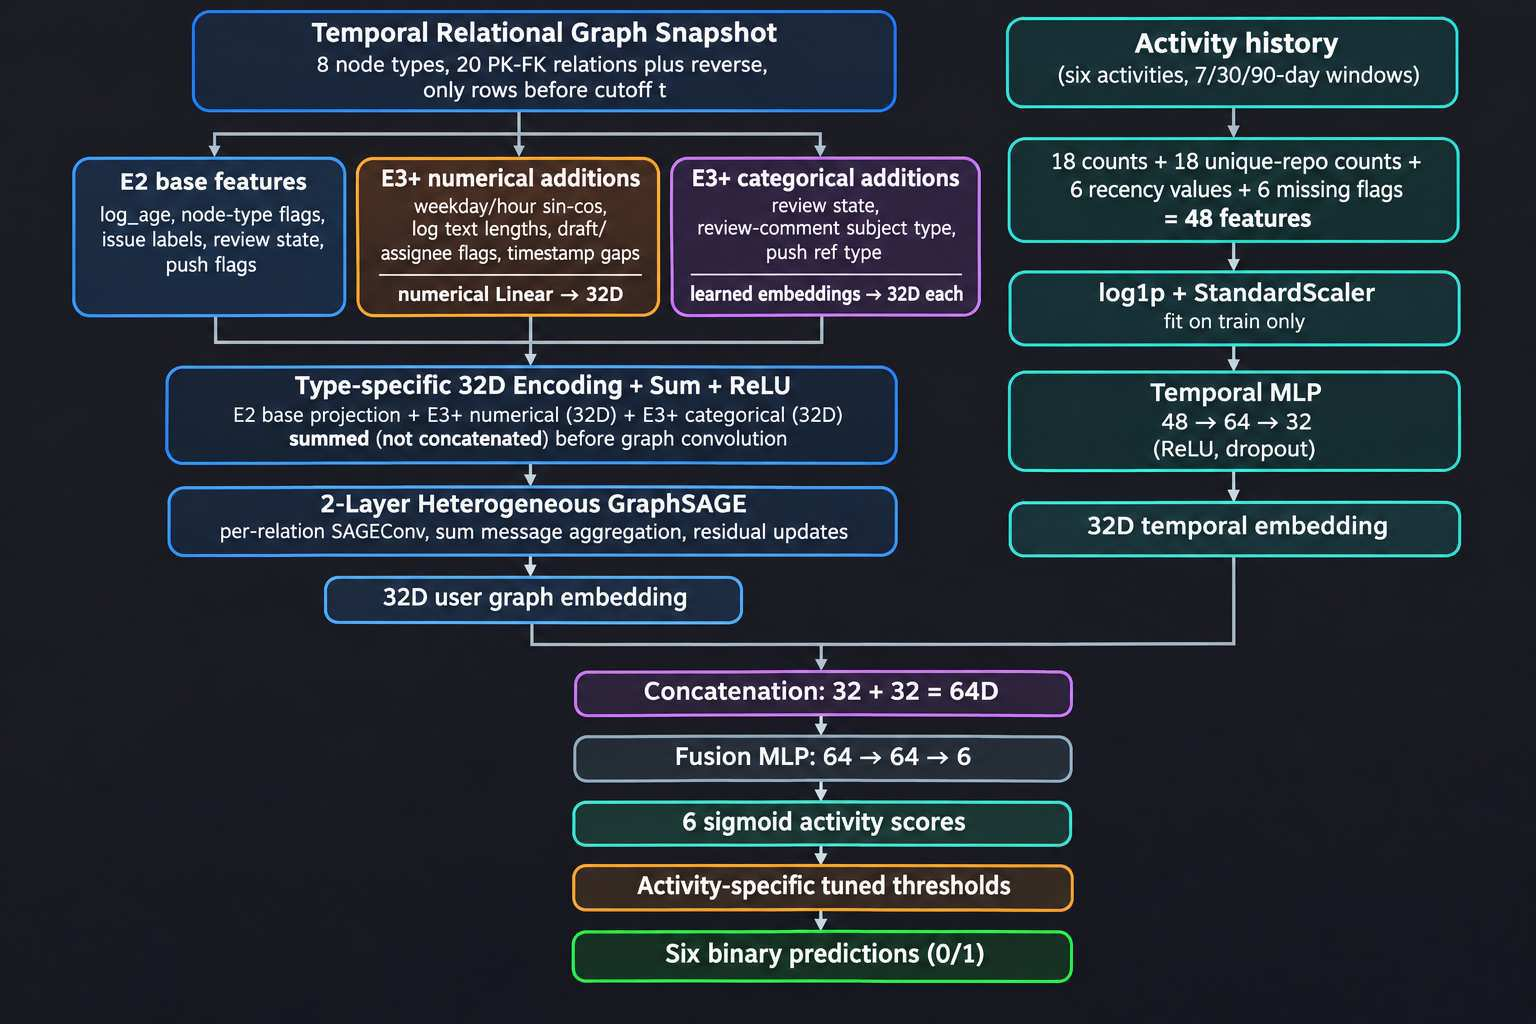

In [ ]:
"""Step 9A: leakage-conscious additional typed column encodings for the NYCU GitHub RDL task.

Assumptions:
  * graph_tables: same dictionaries of eight DataFrames used in Step 6.
  * PKs are row numbers 0..N-1 as in official preprocess.py.
  * create_week_loader() already applies Step 7 add_initial_features().
  * batch[node_type].row_id is the original PK (not the PyG local n_id).
  * pretrained E3 has .encoders, .convs, .temporal_encoder, .head.

This is a SELECTED column-aware encoder, not the full RelBench/TabTransformer stack.
No later-known fields (closed_at, merged_at, merged_by_id, state_reason,
dismissed_at) or unstable identifiers/user logins are used.
"""

ROW_TIME = {
    'users': ('user_id', 'first_seen_at'),
    'repos': ('repo_id', 'first_seen_at'),
    'prs': ('pr_id', 'first_seen_at'),
    'issues': ('issue_id', 'first_seen_at'),
    'issue_comments': ('comment_id', 'created_at'),
    'reviews': ('review_id', 'first_seen_at'),
    'review_comments': ('comment_id', 'created_at'),
    'pushes': ('push_id', 'created_at'),
}

# 0 = missing/other, values 1..K = known category. Fixed a priori.
CATEGORY_VOCABS = {
    'reviews': {
        'state': {'approved': 1, 'changes_requested': 2, 'commented': 3},
    },
    'review_comments': {
        'subject_type': {'line': 1, 'file': 2},
    },
    'pushes': {
        'ref_type': {'branch': 1, 'tag': 2},
    },
}


def _log_num(df, key, max_value=1000000):
    v = pd.to_numeric(df[key], errors='coerce').fillna(0)
    return np.log1p(v.clip(lower=0, upper=max_value).to_numpy(dtype=np.float64)).astype('float32')


def _flag(df, key):
    return df[key].fillna(False).astype('boolean').fillna(False).astype('float32').to_numpy()


def _present(df, key):
    return df[key].notna().astype('float32').to_numpy()


def _log_strlen(df, key, cap=4096):
    lengths = df[key].fillna('').astype('string').str.len().fillna(0).to_numpy(dtype=np.float64)
    return np.log1p(np.clip(lengths, 0, cap)).astype('float32')


def _lag_known_at_first_seen(df, first_seen_col, original_col):
    """Only elapsed time between row appearance and an earlier known timestamp.

    This is not the prediction-time age: that already exists in original x.
    """
    seen = pd.to_datetime(df[first_seen_col], errors='coerce')
    original = pd.to_datetime(df[original_col], errors='coerce')
    delta = (seen - original).dt.total_seconds().div(86400)
    valid = original.notna() & seen.notna() & (delta >= 0)
    days = delta.where(valid, 0).fillna(0).clip(lower=0, upper=3650)
    return np.log1p(days.to_numpy(dtype=np.float64)).astype('float32'), valid.astype('float32').to_numpy()


def _numeric_columns(df, node_type, row_time_col):
    """Stable set of columns, identical regardless of date/snapshot size."""
    t = pd.to_datetime(df[row_time_col], errors='coerce')
    dow = t.dt.dayofweek.fillna(0).to_numpy(dtype=np.float64)
    hour = t.dt.hour.fillna(0).to_numpy(dtype=np.float64)
    columns = OrderedDict([
        ('dow_sin', np.sin(2 * np.pi * dow / 7).astype('float32')),
        ('dow_cos', np.cos(2 * np.pi * dow / 7).astype('float32')),
        ('hour_sin', np.sin(2 * np.pi * hour / 24).astype('float32')),
        ('hour_cos', np.cos(2 * np.pi * hour / 24).astype('float32')),
    ])

    if node_type == 'prs':
        columns.update({
            'log_pr_number': _log_num(df, 'number'),
            'is_cross_repo': _flag(df, 'is_cross_repo'),
            'is_draft': _flag(df, 'draft'),
            'draft_known': _present(df, 'draft'),
            'log_title_len': _log_strlen(df, 'title'),
            'log_head_ref_len': _log_strlen(df, 'head_ref'),
            'log_base_ref_len': _log_strlen(df, 'base_ref'),
        })
        gap, known = _lag_known_at_first_seen(df, 'first_seen_at', 'created_at')
        columns['log_first_seen_after_created_days'] = gap
        columns['created_at_known'] = known
    elif node_type == 'issues':
        columns.update({
            'log_issue_number': _log_num(df, 'number'),
            'has_assignee': _present(df, 'assignee_id'),
            'locked': _flag(df, 'locked'),
            'locked_known': _present(df, 'locked'),
            'log_title_len': _log_strlen(df, 'title'),
            'log_body_len': _log_strlen(df, 'body'),
        })
        gap, known = _lag_known_at_first_seen(df, 'first_seen_at', 'created_at')
        columns['log_first_seen_after_created_days'] = gap
        columns['created_at_known'] = known
    elif node_type == 'issue_comments':
        columns.update({
            'log_body_len': _log_strlen(df, 'body'),
            'via_app_present': _present(df, 'via_app'),
        })
    elif node_type == 'reviews':
        columns['log_body_len'] = _log_strlen(df, 'body')
        gap, known = _lag_known_at_first_seen(df, 'first_seen_at', 'submitted_at')
        columns['log_first_seen_after_submitted_days'] = gap
        columns['submitted_at_known'] = known
    elif node_type == 'review_comments':
        columns.update({
            'log_body_len': _log_strlen(df, 'body'),
            'log_diff_hunk_len': _log_strlen(df, 'diff_hunk'),
            'log_path_len': _log_strlen(df, 'path'),
            'log_position': _log_num(df, 'position'),
            'position_known': _present(df, 'position'),
        })
    elif node_type == 'pushes':
        columns.update({
            'log_branch_len': _log_strlen(df, 'branch'),
        })
    # users: the latest login/is_bot may be backfilled from later events.
    # repos: owner_login and name are latest; org fields may be backfilled.
    # Therefore users and repos use only timestamp-based extras.
    return columns


def build_column_feature_cache(graph_tables):
    """Precompute t-INDEPENDENT extras keyed by *global* row ID.

    No statistics are fitted on future rows, and no future-labelled columns are used.
    Snapshot filtering is still performed by existing create_week_loader().
    """
    cache = {'num': {}, 'cat': {}, 'num_names': {}, 'cat_names': {}, 'cat_sizes': {}}
    for nt, (pk, row_time_col) in ROW_TIME.items():
        df = graph_tables[nt].sort_values(pk).reset_index(drop=True)
        actual_ids = df[pk].to_numpy(dtype=np.int64)
        if not np.array_equal(actual_ids, np.arange(len(df))):
            raise ValueError(f'{nt}: expected official global {pk} values 0..N-1')

        columns = _numeric_columns(df, nt, row_time_col)
        num = np.column_stack(list(columns.values())).astype('float32')
        if num.shape[0] != len(df) or not np.isfinite(num).all():
            raise ValueError(f'{nt}: invalid numeric encodings')
        cache['num'][nt] = torch.from_numpy(num)
        cache['num_names'][nt] = list(columns.keys())

        cat_specs = CATEGORY_VOCABS.get(nt, {})
        cat_columns = []
        for col_name, mapping in cat_specs.items():
            values = df[col_name].astype('string').str.lower()
            cat_columns.append(values.map(mapping).fillna(0).to_numpy(dtype=np.int64))
        cat = (np.column_stack(cat_columns).astype(np.int64)
               if cat_columns else np.empty((len(df), 0), dtype=np.int64))
        cache['cat'][nt] = torch.from_numpy(cat)
        cache['cat_names'][nt] = list(cat_specs.keys())
        cache['cat_sizes'][nt] = {name: max(mapping.values()) + 1
                                  for name, mapping in cat_specs.items()}
    return cache


def enhance_sampled_batch(batch, cache):
    """Call after create_week_loader() yields a CPU batch, BEFORE batch.to(device).

    Original Step 7 node features remain first, then numerical extras are appended.
    PK alignment uses row_id stored on the existing HeteroData nodes.
    """
    for nt in batch.node_types:
        if 'row_id' not in batch[nt]:
            raise KeyError(f'{nt}: batch has no row_id; check Step 6 graph builder')
        ids = batch[nt].row_id.to(dtype=torch.long, device='cpu')
        if ids.numel() and (ids.min() < 0 or ids.max() >= len(cache['num'][nt])):
            raise IndexError(f'{nt}: sampled row_id outside global table')
        original_x = batch[nt].x.float()
        extras = cache['num'][nt].index_select(0, ids)
        if original_x.shape[0] != extras.shape[0]:
            raise ValueError(f'{nt}: feature order/length mismatch')
        batch[nt].x = torch.cat([original_x, extras], dim=-1)
        batch[nt].cat = cache['cat'][nt].index_select(0, ids)
    return batch


class ColumnEnhancedHybrid(nn.Module):
    """E3 backbone + numerical column projections + per-column category embeddings.

    Extra embeddings are zero-initialized, so at initialization this model
    computes the SAME outputs as the supplied pretrained E3 (in eval mode).
    """

    def __init__(self, pretrained_hybrid, cache):
        super().__init__()
        self.backbone = copy.deepcopy(pretrained_hybrid)
        self.base_dims = {}
        self.extra_dims = {}
        self.cat_names = {}
        self.num_projections = nn.ModuleDict()
        self.cat_embeddings = nn.ModuleDict()
        for nt, encoder in self.backbone.encoders.items():
            base = int(encoder.in_features)
            hid = int(encoder.out_features)
            extra = len(cache['num_names'][nt])
            self.base_dims[nt] = base
            self.extra_dims[nt] = extra
            self.cat_names[nt] = cache['cat_names'][nt]
            layer = nn.Linear(extra, hid, bias=False)
            nn.init.zeros_(layer.weight)
            self.num_projections[nt] = layer
            emb = nn.ModuleDict()
            for name, cardinality in cache['cat_sizes'][nt].items():
                table = nn.Embedding(cardinality, hid)
                nn.init.zeros_(table.weight)
                emb[name] = table
            self.cat_embeddings[nt] = emb

    def forward(self, batch, temporal_x):
        h = {}
        for nt, encoder in self.backbone.encoders.items():
            x = batch[nt].x.float()
            base_dim = self.base_dims[nt]
            extra_dim = self.extra_dims[nt]
            if x.shape[1] != base_dim + extra_dim:
                raise ValueError(f'{nt}: expected {base_dim}+{extra_dim} features, got {x.shape[1]}')
            z = encoder(x[:, :base_dim])
            z = z + self.num_projections[nt](x[:, base_dim:])
            if self.cat_names[nt]:
                cat = batch[nt].cat.long()
                if cat.shape[1] != len(self.cat_names[nt]):
                    raise ValueError(f'{nt}: categorical columns mismatch')
                for i, name in enumerate(self.cat_names[nt]):
                    z = z + self.cat_embeddings[nt][name](cat[:, i])
            h[nt] = F.relu(z)

        for conv in self.backbone.convs:
            messages = conv(h, batch.edge_index_dict)
            h = {nt: (F.relu(x + messages[nt]) if nt in messages else x)
                 for nt, x in h.items()}

        n = batch['users'].batch_size
        user_rep = h['users'][:n]
        temporal_rep = self.backbone.temporal_encoder(temporal_x)
        return self.backbone.head(torch.cat([user_rep, temporal_rep], dim=-1))


In [ ]:
# 9A.1 Prepare column encoders

feature_cache = build_column_feature_cache(
    graph_tables
)

for node_type in graph_tables:
    print(
        node_type,
        "extra numerical:",
        len(feature_cache["num_names"][node_type]),
        "categorical:",
        feature_cache["cat_names"][node_type]
    )

users extra numerical: 4 categorical: []
repos extra numerical: 4 categorical: []
prs extra numerical: 13 categorical: []
issues extra numerical: 12 categorical: []
issue_comments extra numerical: 6 categorical: []
reviews extra numerical: 7 categorical: ['state']
review_comments extra numerical: 9 categorical: ['subject_type']
pushes extra numerical: 5 categorical: ['ref_type']


In [ ]:
# 9A.2 — Initialize model

torch.manual_seed(42)

enhanced_model = ColumnEnhancedHybrid(
    pretrained_hybrid=hybrid_model,
    cache=feature_cache
).to(device)

enhanced_optimizer = torch.optim.AdamW(
    enhanced_model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

enhanced_criterion = hybrid_criterion

print(enhanced_model)

ColumnEnhancedHybrid(
  (backbone): HybridTemporalHetGNN(
    (encoders): ModuleDict(
      (users): Linear(in_features=2, out_features=32, bias=True)
      (repos): Linear(in_features=1, out_features=32, bias=True)
      (prs): Linear(in_features=1, out_features=32, bias=True)
      (issues): Linear(in_features=3, out_features=32, bias=True)
      (issue_comments): Linear(in_features=2, out_features=32, bias=True)
      (reviews): Linear(in_features=3, out_features=32, bias=True)
      (review_comments): Linear(in_features=2, out_features=32, bias=True)
      (pushes): Linear(in_features=3, out_features=32, bias=True)
    )
    (convs): ModuleList(
      (0-1): 2 x HeteroConv(num_relations=40)
    )
    (temporal_encoder): Sequential(
      (0): Linear(in_features=48, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.2, inplace=False)
      (3): Linear(in_features=64, out_features=32, bias=True)
      (4): ReLU()
    )
    (head): Sequential(
      (0): Linear(in_fe

In [ ]:
# Sanity check init

hybrid_model.eval()
enhanced_model.eval()

t, week = next(
    iter(val_df.groupby("prediction_time", sort=True))
)

loader, graph, _ = create_week_loader(
    t, week, shuffle=False, batch_size=32
)

batch = next(iter(loader))
n = batch["users"].batch_size

indices = (
    batch["users"].sample_index[:n]
    .cpu().numpy()
)

temporal_x = torch.as_tensor(
    temp_val.loc[indices].to_numpy(dtype=np.float32),
    device=device
)

batch_original = copy.deepcopy(batch).to(device)
batch_enhanced = enhance_sampled_batch(
    batch, feature_cache
).to(device)

with torch.no_grad():
    old_logits = hybrid_model(
        batch_original, temporal_x
    )
    new_logits = enhanced_model(
        batch_enhanced, temporal_x
    )

difference = (
    old_logits - new_logits
).abs().max().item()

print("Maximum difference:", difference)

assert torch.allclose(
    old_logits, new_logits,
    atol=1e-5
)

del loader, graph

Maximum difference: 9.5367431640625e-07


In [ ]:
# 9A.3 Train enhanced hybrid model

ENHANCED_EPOCHS = 3

for epoch in range(ENHANCED_EPOCHS):

    enhanced_model.train()

    total_loss = 0.0
    steps = 0

    for t, week in train_df.groupby(
        "prediction_time",
        sort=True
    ):

        loader, graph, available = create_week_loader(
            t, week,
            shuffle=True,
            batch_size=64
        )

        if loader is None:
            continue

        for batch in loader:

            n = batch["users"].batch_size

            indices = (
                batch["users"]
                .sample_index[:n]
                .cpu()
                .numpy()
            )

            temporal_x = torch.as_tensor(
                temp_train.loc[
                    indices
                ].to_numpy(dtype=np.float32),
                device=device
            )

            # Append richer column encodings
            batch = enhance_sampled_batch(
                batch, feature_cache
            ).to(device)

            logits = enhanced_model(
                batch, temporal_x
            )

            labels = batch["users"].y[:n].float()

            loss = enhanced_criterion(
                logits, labels
            )

            enhanced_optimizer.zero_grad()

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                enhanced_model.parameters(),
                max_norm=1.0
            )

            enhanced_optimizer.step()

            total_loss += loss.item()
            steps += 1

        del loader, graph

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {total_loss / max(steps, 1):.4f}"
    )

Epoch 1: Loss = 0.3697
Epoch 2: Loss = 0.3690
Epoch 3: Loss = 0.3673


## Evaluate & Compare with other models

In [ ]:
# Reusable E3+ inference on ANY cutoff (tuning, benchmark, or final test).
# Uses the frozen scaler learned on train_df; does NOT fit any parameters.
# Unavailable graph users remain all-zero, consistent with prior evaluations.

def predict_e3plus(week_df):

    # Transform features using existing training scaler
    temp_raw = prepare_temporal_features(
        week_df,
        feature_cols
    )

    temp_features = pd.DataFrame(
        scaler.transform(temp_raw).astype("float32"),
        index=week_df.index,
        columns=temp_raw.columns
    )

    probabilities = pd.DataFrame(
        0.0,
        index=week_df.index,
        columns=target_cols
    )

    enhanced_model.eval()

    with torch.no_grad():

        for t, week in week_df.groupby(
            "prediction_time",
            sort=True
        ):

            loader, graph, available = create_week_loader(
                t,
                week,
                shuffle=False,
                batch_size=64
            )

            print(
                t,
                "available users:",
                available,
                "/",
                len(week)
            )

            if loader is None:
                continue

            for batch in loader:

                n = batch["users"].batch_size

                indices = (
                    batch["users"]
                    .sample_index[:n]
                    .cpu()
                    .numpy()
                )

                temporal_x = torch.as_tensor(
                    temp_features.loc[
                        indices
                    ].to_numpy(dtype=np.float32),
                    device=device
                )

                batch = enhance_sampled_batch(
                    batch,
                    feature_cache
                ).to(device)

                logits = enhanced_model(
                    batch,
                    temporal_x
                )

                probs = torch.sigmoid(
                    logits
                ).cpu().numpy()

                probabilities.loc[
                    indices,
                    target_cols
                ] = probs

            del loader, graph

    return probabilities

In [ ]:
# Threshold calibration is performed on exactly one held-out, labeled week.
# This E3+ checkpoint was trained only on the preceding train_df weeks.

# Generate predicted probabilities for threshold tuning
tuning_df = val_df.copy()

tuning_probs = predict_e3plus(tuning_df)

tuning_y = tuning_df[target_cols].astype(int)

# Generate binary prediction 0/1 based on thresh=0.5 (as a baseline comparison)
val_probs_enhanced = tuning_probs.copy()

val_preds_enhanced = (tuning_probs >= 0.5).astype(int)


print("Tuning week:", tuning_df["prediction_time"].iloc[0])

display(tuning_probs.head())

2026-10-17 16:00:00 available users: 7706 / 7745
Tuning week: 2026-10-17 16:00:00


,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
69705,0.119407,0.022652,0.017590,0.013023,0.007229,0.591352
69706,0.354463,0.419520,0.274668,0.201976,0.130660,0.596429
69707,0.026854,0.015164,0.013021,0.006835,0.003369,0.071917
69708,0.633264,0.773371,0.484748,0.110269,0.065987,0.813500
69709,0.813202,0.171777,0.356202,0.081218,0.042867,0.968024


In [ ]:
# Optimize per-activity F1 on TUNING WEEK only. This is not equivalent to
# optimizing the combined (macro-F1+micro-F1)/2 score globally.

# Find the best threshold for each activity

threshold_grid = np.linspace(
    0.05,
    0.95,
    91
)

best_thresholds = {}
tuning_rows = []

for activity in target_cols:

    y_true = tuning_y[activity].to_numpy()

    y_prob = tuning_probs[activity].to_numpy()

    scores = np.array([
        f1_score(
            y_true,
            y_prob >= threshold,
            zero_division=0
        )
        for threshold in threshold_grid
    ])

    best_candidates = threshold_grid[
        np.isclose(scores, scores.max())
    ]

    # Prefer threshold closest to 0.5 in case of ties
    best_threshold = float(
        best_candidates[
            np.argmin(
                np.abs(best_candidates - 0.5)
            )
        ]
    )

    best_thresholds[activity] = best_threshold

    tuning_rows.append({
        "Activity": activity,
        "Best Threshold": best_threshold,
        "F1 (0.5)": f1_score(
            y_true,
            y_prob >= 0.5,
            zero_division=0
        ),
        "Best Tuning F1": scores.max()
    })

threshold_tuning_results = (
    pd.DataFrame(tuning_rows)
    .set_index("Activity")
)

display(threshold_tuning_results.round(4))

,Best Threshold,F1 (0.5),Best Tuning F1
Activity,,,
open_pr,0.55,0.4005,0.4240
open_issue,0.57,0.4756,0.5029
issue_comment,0.60,0.3705,0.3977
pr_review,0.55,0.3712,0.3959
pr_review_comment,0.48,0.3493,0.3644
push,0.53,0.6389,0.6420


In [ ]:
# Add E3 model+ (threshold tuned) to evaluation df

tuned_thresholds = pd.Series(best_thresholds).reindex(target_cols)
val_preds_tuned_enhanced = tuning_probs.ge(tuned_thresholds, axis="columns").astype(int)

enhanced_results_tuned = evaluate_by_week(
    val_preds_tuned_enhanced,
    "E3+ Column Encoding (Tuned)"
)

# Replace previous E3+ Column Encoding (Tuned) rows if this cell is rerun
official_results = pd.concat(
    [
        official_results[
            official_results["Model"] != "E3+ Column Encoding (Tuned)"
        ],
        enhanced_results_tuned
    ],
    ignore_index=True
)

In [ ]:
# Add E3 model+ (NOT threshold tuned) to evaluation df

enhanced_results = evaluate_by_week(
    val_preds_enhanced,
    "E3+ Column Encoding (NOT Tuned)"
)

# Replace previous E3+ Column Encoding (NOT Tuned) rows if this cell is rerun
official_results = pd.concat(
    [
        official_results[
            official_results["Model"] != "E3+ Column Encoding (NOT Tuned)"
        ],
        enhanced_results
    ],
    ignore_index=True
)

In [ ]:
official_results

,Model,Week,Macro-F1,Micro-F1,Score
0,Copy Last Week,2026-10-17 16:00:00,0.382129,0.493922,0.438025
1,LightGBM,2026-10-17 16:00:00,0.359398,0.475330,0.417364
2,E2 Temporal HetGNN,2026-10-17 16:00:00,0.359807,0.459131,0.409469
3,E3 Hybrid HetGNN+Temporal,2026-10-17 16:00:00,0.440209,0.537805,0.489007
4,E3+ Column Encoding (Tuned),2026-10-17 16:00:00,0.454467,0.552280,0.503373
5,E3+ Column Encoding (NOT Tuned),2026-10-17 16:00:00,0.434335,0.535915,0.485125


In [ ]:
model_comparison = (
    official_results
    .groupby("Model")[
        ["Macro-F1", "Micro-F1", "Score"]
    ]
    .mean()
    .sort_values("Score", ascending=False)
)

model_comparison.round(4)

,Macro-F1,Micro-F1,Score
Model,,,
E3+ Column Encoding (Tuned),0.4545,0.5523,0.5034
E3 Hybrid HetGNN+Temporal,0.4402,0.5378,0.4890
E3+ Column Encoding (NOT Tuned),0.4343,0.5359,0.4851
Copy Last Week,0.3821,0.4939,0.4380
LightGBM,0.3594,0.4753,0.4174
E2 Temporal HetGNN,0.3598,0.4591,0.4095


## Benchmark results of Sep 27-Oct 4 week

In [ ]:
if RUN_MODE == "benchmark":
    # Held-out Sep 27–Oct 4 benchmark. We keep the model and fitted scaler fixed.
    benchmark_df = dataset.loc[dataset["prediction_time"] == benchmark_t].copy()
    assert benchmark_df["prediction_time"].nunique() == 1
    print("Benchmark cutoff:", benchmark_df["prediction_time"].unique())
else:
    benchmark_df = None
    print("FINAL MODE: skip September benchmark (would use future-trained weights).")

FINAL MODE: skip September benchmark (would use future-trained weights).


In [ ]:
if RUN_MODE == "benchmark":
    benchmark_probs = predict_e3plus(benchmark_df)

    # Original threshold = 0.5
    val_preds_05 = (benchmark_probs >= 0.5).astype(int)

    # Tuned thresholds from Sep 20 week
    threshold_series = pd.Series(best_thresholds).reindex(target_cols)
    assert threshold_series.notna().all()

    val_preds_tuned = benchmark_probs.ge(threshold_series, axis="columns").astype(int)

In [ ]:
if RUN_MODE == "benchmark":
    # evaluate_by_week reads val_df, so temporarily pass the right evaluation set.
    _prior_val_df = val_df

    try:
        val_df = benchmark_df
        results_05 = evaluate_by_week(val_preds_05,
                                      "E3+ Model (0.5)")
        results_tuned = evaluate_by_week(val_preds_tuned,
                                         "E3+ Model (Tuned)")

    finally:
        val_df = _prior_val_df  # restore tuning week for downstream diagnostics

    threshold_comparison = pd.concat([results_05, results_tuned], ignore_index=True)

    display(threshold_comparison.round(4))

In [ ]:
if RUN_MODE == "benchmark":
    rows = []

    for activity in target_cols:
        actual = benchmark_df[activity].astype(int)

        baseline_f1 = f1_score(actual,
                               val_preds_05[activity],
                               zero_division=0)

        tuned_f1 = f1_score(actual,
                            val_preds_tuned[activity],
                            zero_division=0)

        rows.append({
            "Activity": activity,
            "Threshold": best_thresholds[activity],
            "F1 (0.5)": baseline_f1,
            "F1 (Tuned)": tuned_f1,
            "Difference": tuned_f1 - baseline_f1,
        })

    threshold_diagnostics = pd.DataFrame(rows).set_index("Activity")

    display(threshold_diagnostics.round(4))

In [ ]:
# # Check activity distribution across weeks

# weekly_label_stats = (
#     dataset
#     .groupby("prediction_time")[target_cols]
#     .mean()
#     .mul(100)
#     .round(2)
# )

# weekly_label_stats.insert(
#     0,
#     "n_users",
#     dataset.groupby("prediction_time").size()
# )

# display(weekly_label_stats)

In [ ]:
# # Check whether there are missing activities for particular days

# from pathlib import Path
# import gzip

# raw_dir = Path("/content/RAW_DATA_FOLDER")

# dates = [
#     "2026-10-01",
#     "2026-10-22",
#     "2026-10-27",
#     "2026-10-29",
#     "2026-11-03",
# ]

# for date in dates:

#     path = raw_dir / f"{date}-12.json.gz"

#     if not path.exists():
#         print(date, "FILE MISSING")
#         continue

#     with gzip.open(path, "rb") as f:
#         count = sum(1 for _ in f)

#     print(date, f"{count:,} events")

In [ ]:
# # 1. Zip the folder (replace 'your_folder' with your folder's path)
# !zip -r /content/data_jun_nov.zip /content/assignment2/data

# # 2. Download the zipped file
# from google.colab import files
# files.download('/content/data_jun_nov.zip')

# Step 10A Per activity evaluation & temporal leakage audit

## Step 10A.1 Per activity F1 comparison

In [ ]:
truth = val_df[target_cols].astype(int)

models = {
    "LightGBM": val_preds,
    "E2 HetGNN": val_preds_gnn,
    "E3 Hybrid": val_preds_hybrid,
    "E3+ Column Encoding (Tuned)": val_preds_tuned_enhanced,
    "E3+ Column Encoding (NOT Tuned)": val_preds_enhanced,
}

rows = []

for activity in target_cols:

    row = {
        "Activity": activity,
        "Actual Positive Rate": truth[activity].mean(),
    }

    for model_name, predictions in models.items():

        pred = predictions.loc[
            truth.index, activity
        ].astype(int)

        row[model_name] = f1_score(
            truth[activity],
            pred,
            zero_division=0
        )

    rows.append(row)

per_activity_comparison = (
    pd.DataFrame(rows)
    .set_index("Activity")
)

display(per_activity_comparison.round(4))

,Actual Positive Rate,LightGBM,E2 HetGNN,E3 Hybrid,E3+ Column Encoding (Tuned),E3+ Column Encoding (NOT Tuned)
Activity,,,,,,
open_pr,0.0449,0.3305,0.3135,0.4035,0.4219,0.4005
open_issue,0.0305,0.3988,0.4139,0.4820,0.4887,0.4756
issue_comment,0.0274,0.2920,0.2643,0.3921,0.3665,0.3705
pr_review,0.0291,0.3364,0.2995,0.3614,0.3884,0.3712
pr_review_comment,0.0221,0.2396,0.2822,0.3659,0.3248,0.3493
push,0.2386,0.5590,0.5854,0.6365,0.6420,0.6389


In [ ]:
# Precision and recall help explain what the F1-score hides, especially for
# rare activities; uses tuning week and threshold 0.5 for a clean comparison.

rows = []

for activity in target_cols:

    actual = truth[activity]

    predicted = val_preds_tuned_enhanced.loc[
        truth.index, activity
    ].astype(int)

    rows.append({
        "Activity": activity,
        "Actual Positive Rate": actual.mean(),
        "Predicted Positive Rate": predicted.mean(),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        ),
    })

e3plus_diagnostics = (
    pd.DataFrame(rows)
    .set_index("Activity")
)

display(e3plus_diagnostics.round(4))

,Actual Positive Rate,Predicted Positive Rate,Precision,Recall,F1
Activity,,,,,
open_pr,0.0449,0.0469,0.4132,0.4310,0.4219
open_issue,0.0305,0.0435,0.4154,0.5932,0.4887
issue_comment,0.0274,0.0297,0.3522,0.3821,0.3665
pr_review,0.0291,0.0514,0.3040,0.5378,0.3884
pr_review_comment,0.0221,0.0336,0.2692,0.4094,0.3248
push,0.2386,0.2702,0.6044,0.6845,0.6420


## 10A.2 Verify temporal graph snapshots

In [ ]:
for t, week in val_df.groupby(
    "prediction_time",
    sort=True
):

    loader, graph, available = create_week_loader(
        t,
        week,
        shuffle=False,
        batch_size=64
    )

    assert graph is not None

    print(f"\nPrediction cutoff: {t}")

    for node_type, (pk, time_col) in ROW_TIME.items():

        row_ids = (
            graph[node_type]
            .row_id
            .cpu()
            .numpy()
        )

        source = graph_tables[node_type].set_index(pk)

        times = pd.to_datetime(
            source.loc[row_ids, time_col]
        )

        invalid = times.isna() | (times >= t)

        print(
            f"{node_type:18s}",
            f"nodes={len(row_ids):7d}",
            f"invalid={invalid.sum()}"
        )

        assert invalid.sum() == 0, (
            f"Temporal leakage in {node_type}"
        )

    del loader, graph

print("\nAll graph snapshots passed!")


Prediction cutoff: 2026-10-17 16:00:00
users              nodes=  14185 invalid=0
repos              nodes=  46608 invalid=0
prs                nodes=  53650 invalid=0
issues             nodes=  34263 invalid=0
issue_comments     nodes=  18781 invalid=0
reviews            nodes=  14737 invalid=0
review_comments    nodes=  11421 invalid=0
pushes             nodes= 466784 invalid=0

All graph snapshots passed!


## 10A.3 Verify feature column encoding

In [ ]:
for node_type in graph_tables:

    print(f"\n{node_type}")

    print(
        "Numerical/timestamp:",
        feature_cache["num_names"][node_type]
    )

    print(
        "Categorical:",
        feature_cache["cat_names"][node_type]
    )


users
Numerical/timestamp: ['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos']
Categorical: []

repos
Numerical/timestamp: ['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos']
Categorical: []

prs
Numerical/timestamp: ['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos', 'log_pr_number', 'is_cross_repo', 'is_draft', 'draft_known', 'log_title_len', 'log_head_ref_len', 'log_base_ref_len', 'log_first_seen_after_created_days', 'created_at_known']
Categorical: []

issues
Numerical/timestamp: ['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos', 'log_issue_number', 'has_assignee', 'locked', 'locked_known', 'log_title_len', 'log_body_len', 'log_first_seen_after_created_days', 'created_at_known']
Categorical: []

issue_comments
Numerical/timestamp: ['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos', 'log_body_len', 'via_app_present']
Categorical: []

reviews
Numerical/timestamp: ['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos', 'log_body_len', 'log_first_seen_after_submitted_days', 'submitted_at_known']
Categorical: ['state'

# Step 11 Final Test Prediction & Submission

In [ ]:
# No redefinition of prediction_times here! The final training cutoff is already
# configured in Step 3 (RUN_MODE="final") and applied in Step 5.
# Redefining prediction_times at this late point would NOT rebuild samples,
# features, train_df, scaler or model weights, and would silently create a mismatch.

assert RUN_MODE == "final", (
    "Step 11 creates the official November submission. Set RUN_MODE='final' "
    "in Step 3 and rerun from there through E3+ training/tuning."
)
assert train_df["prediction_time"].nunique() == 9

assert tuning_df["prediction_time"].nunique() == 1

print("Final E3+ trained on:", train_df["prediction_time"].nunique(), "weekly cutoffs")
print("Final tuning cutoff:", tuning_df["prediction_time"].iloc[0])

Final E3+ trained on: 9 weekly cutoffs
Final tuning cutoff: 2026-10-17 16:00:00


In [ ]:
# 11.1 Final prediction cutoff, derived from Taiwan local midnight (no hardcoded UTC hour)
final_t_tw = pd.Timestamp("2026-11-22", tz="Asia/Taipei")

final_t = final_t_tw.tz_convert("UTC").tz_localize(None)

submission_deadline_tw = pd.Timestamp("2026-11-21 23:55", tz="Asia/Taipei")

print("Official prediction week starts:", final_t_tw)
print("Comparison cutoff (UTC-naive):", final_t)
print("Submission deadline:", submission_deadline_tw)
print("NOTICE: raw files must have been available before the deadline, not after it.")

Official prediction week starts: 2026-11-22 00:00:00+08:00
Comparison cutoff (UTC-naive): 2026-11-21 16:00:00
Submission deadline: 2026-11-21 23:55:00+08:00
NOTICE: raw files must have been available before the deadline, not after it.


In [ ]:
# The only ID accepted by the official evaluator is github_user_id (masked),
# NOT the internal Users.user_id which may change after preprocessing.

# 11.2 — Load official test users

ASSIGNMENT_DIR = Path("/content/assignment2")

test_input_path = (
    ASSIGNMENT_DIR / "submission/test_input.csv"
)

test_input = pd.read_csv(
    test_input_path,
    dtype={"UserID": "int64"}
)

assert test_input.columns.tolist() == ["UserID"]
assert test_input["UserID"].is_unique
assert test_input["UserID"].notna().all()

print("Official test users:", len(test_input))

display(test_input.head())


Official test users: 4465


,UserID
0,100431196554039
1,100457905686263
2,101051236896852
3,101306412508088
4,101380187937965


In [ ]:
def create_test_features(t, test_input, cohort_users):
    """Use the SAME historical feature builder and schema as training.

    `create_week_loader()` currently requires labels on its input even during
    inference, so we attach six dummy zeros; they are never used to fit weights
    or score November (ground truth does not exist yet).
    """
    features = create_features_for_time(t, cohort_users)

    # Match by stable anonymized GitHub ID, preserving test_input order.
    test_features = test_input.merge(
        features, left_on="UserID", right_on="github_user_id",
        how="left", sort=False, validate="one_to_one"
    )

    missing_users = test_features["user_id"].isna()
    print("Official users missing from processed Users:", int(missing_users.sum()))

    test_features = test_features.loc[~missing_users].copy().reset_index(drop=True)

    test_features["user_id"] = test_features["user_id"].astype("int64")

    test_features["prediction_time"] = t

    for col in target_cols:
        test_features[col] = 0  # loader compatibility only; not true labels

    # All historical features must be present; missing recencies use sentinel 999.
    assert test_features[feature_cols].notna().all().all()
    return test_features

In [ ]:
test_df = create_test_features(
    final_t,
    test_input,
    cohort_users
)

print("Test feature shape:", test_df.shape)

display(
    test_df[
        ["UserID", "user_id", "prediction_time"]
    ].head()
)

Official users missing from processed Users: 0
Test feature shape: (4465, 52)


,UserID,user_id,prediction_time
0,100431196554039,769,2026-11-21 16:00:00
1,100457905686263,5533,2026-11-21 16:00:00
2,101051236896852,2237,2026-11-21 16:00:00
3,101306412508088,8927,2026-11-21 16:00:00
4,101380187937965,62,2026-11-21 16:00:00


In [ ]:
# 11.4 Reuse exactly the SAME E3+ inference function as for tuning.
# It scales with the training-only scaler and applies the column feature cache.
# For test users without a graph node at t, probabilities stay zero.
# No retraining or refitting happens here.

predict_test_e3plus = predict_e3plus

In [ ]:
# Run only after re-preprocessing all eligible raw data before the official
# deadline, then reloading graph_tables, feature_cache and retraining the model.

test_probs = predict_test_e3plus(test_df)

assert np.isfinite(test_probs.to_numpy()).all()

display(test_probs.head())

2026-11-21 16:00:00 available users: 4465 / 4465


,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
0,0.270001,0.728296,0.286058,0.019863,0.010174,0.574869
1,0.005648,0.004113,0.001895,0.003541,0.001445,0.051667
2,0.015926,0.009967,0.005769,0.009800,0.004117,0.161196
3,0.009274,0.023267,0.005057,0.003744,0.001613,0.075607
4,0.321888,0.566240,0.465367,0.039126,0.032282,0.503871


In [ ]:
# Keep thresholds tuned on October, not on the unknown November test labels.
# The final all-zero fallback guarantees output for every official test UserID.

# 11.5 — Apply best thresholds dan generate submission CSV

threshold_series = pd.Series(
    best_thresholds
).reindex(target_cols)

assert threshold_series.notna().all()
assert threshold_series.between(0, 1).all()

test_preds = (
    test_probs.ge(
        threshold_series,
        axis="columns"
    )
).astype(int)

# Attach predictions to their original UserID
known_predictions = test_df[
    ["UserID"]
].copy()

known_predictions[target_cols] = (
    test_preds[target_cols].to_numpy()
)

# Preserve every official test user
submission = test_input.merge(
    known_predictions,
    on="UserID",
    how="left",
    sort=False,
    validate="one_to_one"
)

# Users absent from the processed data:
# all-zero cold-start fallback
missing_prediction_rows = (
    submission[target_cols].isna().all(axis=1)
)

print(
    "Cold-start users absent from tables:",
    missing_prediction_rows.sum()
)

submission[target_cols] = (
    submission[target_cols]
    .fillna(0)
    .astype(int)
)

submission = submission[
    ["UserID"] + target_cols
]

assert len(submission) == len(test_input)
assert submission["UserID"].tolist() == test_input["UserID"].tolist()
assert submission["UserID"].is_unique
assert submission.notna().all().all()
assert submission[target_cols].isin([0, 1]).all().all()

display(submission.head())

Cold-start users absent from tables: 0


,UserID,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
0,100431196554039,0,1,0,0,0,1
1,100457905686263,0,0,0,0,0,0
2,101051236896852,0,0,0,0,0,0
3,101306412508088,0,0,0,0,0,0
4,101380187937965,0,0,0,0,0,0


In [ ]:
# Double-check the student ID / destination before submitting.
# If raw November data are incomplete, this is only a DRAFT output; regenerate
# after final preprocessing. Do not publish a premature CSV as the final answer.

STUDENT_ID = "315540042"

output_path = (
    ASSIGNMENT_DIR /
    f"output_{STUDENT_ID}.csv"
)

submission.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)

Saved: /content/assignment2/output_315540042.csv


In [ ]:
# Official evaluate.py with --input checks format and UserID coverage; it
# cannot calculate November F1 before November ground truth exists.

# 11.6 — Validate submission with official evaluator
result = subprocess.run(
    [
        "python",
        str(ASSIGNMENT_DIR / "scripts/evaluate.py"),
        "--pred",
        str(output_path),
        "--input",
        str(test_input_path),
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

assert result.returncode == 0, "Submission format check failed"


Format check: no errors (4465 users)




In [ ]:
# diagnostic

submission_stats = pd.DataFrame({
    "Predicted Positive Rate (%)":
        submission[target_cols].mean() * 100
})

display(submission_stats.round(2))

,Predicted Positive Rate (%)
open_pr,0.90
open_issue,1.72
issue_comment,0.38
pr_review,1.61
pr_review_comment,1.41
push,6.43


# Step 12 — Q1–Q4 report preparation

The revised assignment grades Q1 schema graph (all 8 tables + **every FK** and PK), Q2 inter-table relationships, Q3 temporal enhancements, and Q4 the end-to-end framework. The next cells generate **editable Graphviz figures** and report-supporting tables. Figures are derived from notebook specs rather than manually retyping FK links.

**Course requirements:** report <=16 slides/pages; video 16–20 min; cite GH Archive in README; make claims only about configurations and results actually run.

In [ ]:
# Report results from ONE coherent time split/configuration.
# In benchmark mode, report 0.5 vs tuned thresholds on Sep 27.
# In final mode, November test has no labels: report October tuning scores,
# clearly labeled IN-SAMPLE for threshold selection (not unbiased benchmark).

if RUN_MODE == "benchmark":
    report_results = threshold_comparison[["Model", "Week", "Macro-F1", "Micro-F1", "Score"]].copy()
else:
    tuning_preds_05 = (tuning_probs >= 0.5).astype(int)

    tuned_thresholds = pd.Series(best_thresholds).reindex(target_cols)
    tuning_preds_tuned = tuning_probs.ge(tuned_thresholds, axis="columns").astype(int)

    report_results = pd.concat([
        evaluate_by_week(tuning_preds_05, "E3+ tuning week (0.5)"),
        evaluate_by_week(tuning_preds_tuned, "E3+ tuning week (selected thresholds)"),
    ], ignore_index=True)[["Model", "Week", "Macro-F1", "Micro-F1", "Score"]]
    print("CAUTION: Optimistic tuning-week scores; not a held-out test benchmark.")
display(report_results.round(4))

CAUTION: Optimistic tuning-week scores; not a held-out test benchmark.


,Model,Week,Macro-F1,Micro-F1,Score
0,E3+ tuning week (0.5),2026-10-17 16:00:00,0.4343,0.5359,0.4851
1,E3+ tuning week (selected thresholds),2026-10-17 16:00:00,0.4545,0.5523,0.5034


In [ ]:
# 12.0 Save final trained model artifacts for reproducibility.
# The feature-cache is regenerated by `build_column_feature_cache(graph_tables)`
# using EXACTLY the same officially preprocessed tables and cutoff convention.

artifacts_dir = ASSIGNMENT_DIR / "model_artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

torch.save(enhanced_model.state_dict(), artifacts_dir / "e3plus_weights.pt")
joblib.dump(scaler, artifacts_dir / "temporal_scaler.joblib")
joblib.dump({
    "run_mode": RUN_MODE,
    "feature_cols": feature_cols,
    "target_cols": target_cols,
    "thresholds": best_thresholds,
    "prediction_cutoff_utc_naive": final_t,
    "train_cutoffs_utc_naive": train_df["prediction_time"].drop_duplicates().tolist(),
    "tuning_cutoff_utc_naive": tuning_t,
    "neighbor_sampling": [16, 8],
    "graph_hidden_size": 32,
    "model": "E3+ ColumnEnhancedHybrid",
}, artifacts_dir / "e3plus_config.joblib")
print("Saved model/scaler/config under:", artifacts_dir)

Saved model/scaler/config under: /content/assignment2/model_artifacts


## Q1 — Schema graph: 8 tables, 20 PK→FK relationships, and dataset coverage

This diagram shows each of the **eight tables**, their **primary key** (blue), every **foreign key** (red), and arrows from each FK to its referenced PK. Edge direction is *child table → referenced parent table*, as required. The notebook's GNN internally adds reverse edges separately. A schema graph (8 table nodes) is not the same as the entity graph (one node per row).

In [ ]:
output_dir = Path("/content/report_figures")
output_dir.mkdir(parents=True, exist_ok=True)

def save_report_figure(graph, filename):
    """Export both SVG (sharp for slides/PDF) and PNG, then show SVG."""
    for fmt in ("svg", "png"):
        graph.render(filename=filename, directory=str(output_dir), format=fmt, cleanup=True)
    display(SVG(filename=str(output_dir / f"{filename}.svg")))

# Validate the diagram
assert len(TABLE_SPECS) == 8
assert len(FK_RELATIONS) == 20

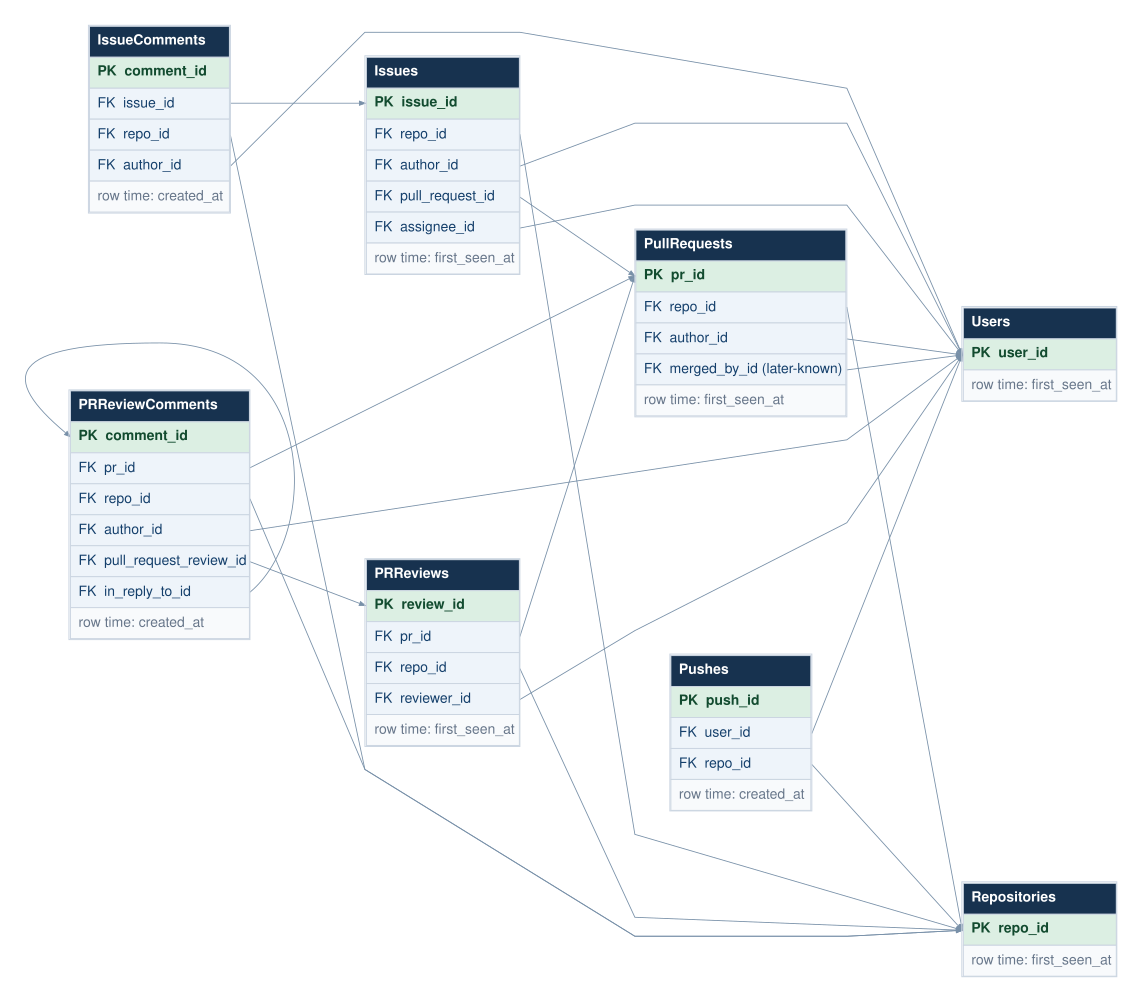

In [ ]:
# Step 12 — Q1: Database Schema Graph
# Reuse TABLE_SPECS and FK_RELATIONS from Step 6.

def make_q1_schema():

  # Display names only, not a second schema definition
  display_names = {
      "users": "Users",
      "repos": "Repositories",
      "prs": "PullRequests",
      "issues": "Issues",
      "issue_comments": "IssueComments",
      "reviews": "PRReviews",
      "review_comments": "PRReviewComments",
      "pushes": "Pushes",
  }

  schema = Digraph(
      "schema",
      graph_attr={
          "rankdir": "LR",
          "splines": "polyline",
          "pad": "0.35",
          "nodesep": "0.65",
          "ranksep": "1.6",
          "overlap": "false",
          "outputorder": "edgesfirst",
          "bgcolor": "white",
      },
      node_attr={
          "shape": "plain",
          "fontname": "Helvetica",
      },
      edge_attr={
          "color": "#7890A8",
          "penwidth": "0.85",
          "arrowsize": "0.6",
      }
  )

  # 1. Generate nodes from existing TABLE_SPECS
  for table_name, (pk, time_col) in TABLE_SPECS.items():

      rows = [
          f'<TR><TD BGCOLOR="#17324F" ALIGN="LEFT">'
          f'<FONT COLOR="white"><B>{display_names[table_name]}</B></FONT>'
          f'</TD></TR>',

          f'<TR><TD PORT="{pk}" ALIGN="LEFT" BGCOLOR="#DCEFE3">'
          f'<FONT COLOR="#124B2F"><B>PK  {pk}</B></FONT>'
          f'</TD></TR>',
      ]

      # Get foreign keys from existing FK_RELATIONS
      for child, fk, parent, known_at in FK_RELATIONS:

          if child != table_name:
              continue

          suffix = " (later-known)" if known_at else ""

          rows.append(
              f'<TR><TD PORT="{fk}" ALIGN="LEFT" BGCOLOR="#EEF4FA">'
              f'<FONT COLOR="#143F6B">FK  {fk}{suffix}</FONT>'
              f'</TD></TR>'
          )

      # Show row availability timestamp
      rows.append(
          f'<TR><TD ALIGN="LEFT" BGCOLOR="#F8FAFC">'
          f'<FONT COLOR="#67768A">row time: {time_col}</FONT>'
          f'</TD></TR>'
      )

      label = (
          '<<TABLE BORDER="1" CELLBORDER="1" '
          'CELLSPACING="0" CELLPADDING="7" COLOR="#CBD5E1">'
          + "".join(rows)
          + '</TABLE>>'
      )

      schema.node(table_name, label=label)


  # 2. Generate FK -> PK edges from existing FK_RELATIONS
  for child, fk, parent, known_at in FK_RELATIONS:

      parent_pk = TABLE_SPECS[parent][0]

      schema.edge(
          f"{child}:{fk}:e",
          f"{parent}:{parent_pk}:w",
          constraint="false" if child == parent else "true"
      )

  # 3. Export PNG and SVG
  for fmt in ["png", "svg"]:
      schema.render(
          filename="q1_schema_graph",
          directory=str(output_dir),
          format=fmt,
          cleanup=True
      )

  save_report_figure(schema, "q1_schema_graph")



# Run to create Q1 figure
make_q1_schema()

In [ ]:
# Q1 dataset coverage: actual raw files (not just observed table row timestamps).

raw_dir = Path("/content/RAW_DATA_FOLDER")
raw_hour_files = list(raw_dir.glob("????-??-??-*.json.gz"))
raw_hours = []
for path in raw_hour_files:
    parts = path.name[:-8].split("-")  # trim '.json.gz'; YYYY-MM-DD-H
    if len(parts) == 4 and all(x.isdigit() for x in parts):
        y, m, d, h = map(int, parts)
        try:
            raw_hours.append(pd.Timestamp(datetime(y, m, d, h)))
        except (ValueError, OverflowError):
            pass
if raw_hours:
    print("Raw GH Archive coverage (UTC hourly filenames):", min(raw_hours), "to", max(raw_hours))
    print("Number of hourly files:", len(raw_hours), "Unique hours:", len(set(raw_hours)))
else:
    print("Raw files unavailable locally: report the documented original download span.")

# Observed entity rows in the currently loaded 8 Parquet tables
coverage_rows = []
for nt, (pk, time_col) in TABLE_SPECS.items():
    ts = pd.to_datetime(graph_tables[nt][time_col]).dropna()
    coverage_rows.append({"Table": TABLE_DISPLAY[nt], "Rows": len(graph_tables[nt]),
                          "Earliest observed": ts.min(), "Latest observed": ts.max()})
dataset_coverage_report = pd.DataFrame(coverage_rows)
display(dataset_coverage_report)


Raw files unavailable locally: report the documented original download span.


,Table,Rows,Earliest observed,Latest observed
0,Users,14834,2026-06-01 00:00:03,2026-11-11 21:46:59
1,Repositories,48563,2026-06-01 00:00:03,2026-11-11 23:10:44
2,PullRequests,60262,2026-06-01 00:00:44,2026-11-11 23:54:45
3,Issues,38320,2026-06-01 00:02:11,2026-11-11 23:54:55
4,IssueComments,20329,2026-06-01 00:09:54,2026-11-11 23:54:55
5,PRReviews,16387,2026-06-01 00:14:58,2026-11-11 23:54:45
6,PRReviewComments,12061,2026-06-01 00:02:00,2026-11-11 23:48:09
7,Pushes,478598,2026-06-01 00:00:03,2026-11-11 23:11:05


## Q2 — Relational modeling (graph construction and message passing)

The relational schema yields 20 **forward FK edges**, augmented with 20 reverse edge types for message passing (40 directed relation types). A temporal graph snapshot includes only rows available before cutoff `t`. Type-specific linear encoders, additional typed column encoders (numerical + categorical), and two heterogeneous GraphSAGE layers produce user graph embeddings. This describes our implementation, not a claim that every RDL baseline uses exactly the same setup.

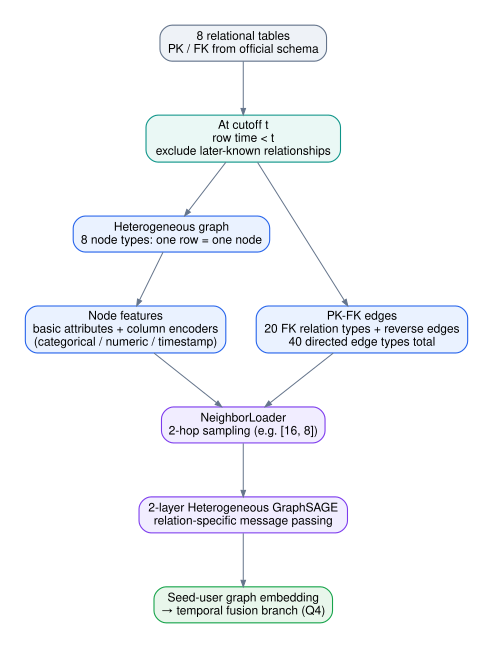

In [ ]:
def make_q2_relational():
    # Original first-version styling: vertical flow + blue/purple/green sections.
    g = Digraph("relational", graph_attr={
        "rankdir": "TB", "pad": "0.35", "ranksep": "0.75", "nodesep": "0.42",
        "bgcolor": "white", "fontname": "Helvetica", "fontsize": "15",
    }, node_attr={
        "shape": "box", "style": "rounded,filled", "fontname": "Helvetica",
        "fontsize": "12", "penwidth": "1.1",
    }, edge_attr={"color": "#64748B", "arrowsize": "0.65"})
    g.node("db", f"{len(TABLE_SPECS)} relational tables\nPK / FK from official schema",
           fillcolor="#EEF2F7", color="#64748B")
    g.node("snapshot", "At cutoff t\nrow time < t\nexclude later-known relationships",
           fillcolor="#EAF8F5", color="#0D9488")
    g.node("nodes", f"Heterogeneous graph\n{len(TABLE_SPECS)} node types: one row = one node",
           fillcolor="#EAF2FF", color="#2563EB")
    g.node("fk", f"PK-FK edges\n{len(FK_RELATIONS)} FK relation types + reverse edges\n"
           f"{2 * len(FK_RELATIONS)} directed edge types total",
           fillcolor="#EAF2FF", color="#2563EB")
    g.node("encoding", "Node features\nbasic attributes + column encoders\n"
           "(categorical / numeric / timestamp)", fillcolor="#EAF2FF", color="#2563EB")
    g.node("sample", "NeighborLoader\n2-hop sampling (e.g. [16, 8])",
           fillcolor="#F1EDFF", color="#7C3AED")
    g.node("gnn", "2-layer Heterogeneous GraphSAGE\nrelation-specific message passing",
           fillcolor="#F1EDFF", color="#7C3AED")
    g.node("user", "Seed-user graph embedding\n→ temporal fusion branch (Q4)",
           fillcolor="#E8F6EB", color="#16A34A")
    for a, b in [("db", "snapshot"), ("snapshot", "nodes"),
                 ("snapshot", "fk"), ("nodes", "encoding"),
                 ("encoding", "sample"), ("fk", "sample"),
                 ("sample", "gnn"), ("gnn", "user")]:
        g.edge(a, b)
    save_report_figure(g, "q2_relational_modeling")

# Run to create Q2 figure
make_q2_relational()

## Q3 — Temporal modeling (time encoding and historical aggregation)

**Node-level time:** `log1p(age_days)` based on each row's availability timestamp; extra `day-of-week`, `hour-of-day`, and timestamp-derived features added by Step 9A. **User-level history:** counts, unique repos in 7/30/90-day lookbacks and six activity-recency features. PR/issue/review historical activity uses actual action time **and** row availability; the 7-day future label is separate. We report the observed GH Archive data gaps as a limitation, not as proof of a model improvement.

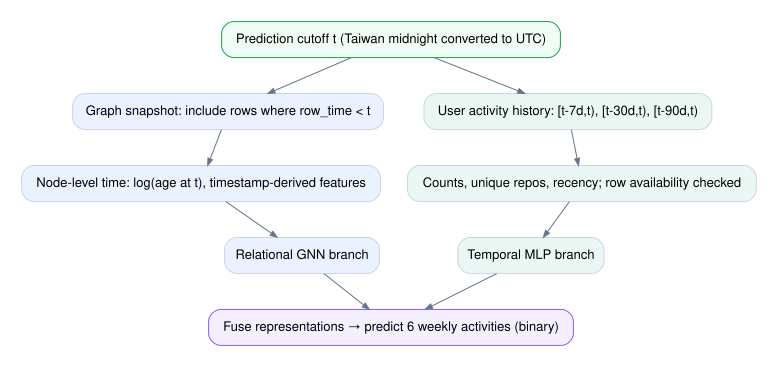

In [ ]:
def make_q3_temporal():
    # Original first-version styling: separate temporal GNN and user-history paths.
    g = Digraph("temporal", graph_attr={
        "rankdir": "TB", "pad": "0.3", "nodesep": "0.38", "ranksep": "0.5",
        "bgcolor": "white", "fontname": "Helvetica",
    }, node_attr={
        "shape": "box", "style": "rounded,filled", "fontname": "Helvetica",
        "fontsize": "13", "color": "#CBD5E1", "fillcolor": "#F8FAFC",
    }, edge_attr={"color": "#64748B", "arrowsize": "0.7"})
    g.node("cut", "Prediction cutoff t (Taiwan midnight converted to UTC)",
           fillcolor="#F0FDF4", color="#16A34A")
    g.node("row", "Graph snapshot: include rows where row_time < t", fillcolor="#EAF2FF")
    g.node("node", "Node-level time: log(age at t), timestamp-derived features", fillcolor="#EAF2FF")
    g.node("window", "User activity history: [t-7d,t), [t-30d,t), [t-90d,t)", fillcolor="#EAF8F5")
    g.node("stats", "Counts, unique repos, recency; row availability checked", fillcolor="#EAF8F5")
    g.node("gnn", "Relational GNN branch", fillcolor="#EAF2FF")
    g.node("mlp", "Temporal MLP branch", fillcolor="#EAF8F5")
    g.node("fusion", "Fuse representations → predict 6 weekly activities (binary)",
           fillcolor="#F5F0FF", color="#8B5CF6")
    for a, b in [("cut", "row"), ("row", "node"), ("node", "gnn"),
                 ("cut", "window"), ("window", "stats"), ("stats", "mlp"),
                 ("gnn", "fusion"), ("mlp", "fusion")]:
        g.edge(a, b)
    save_report_figure(g, "q3_temporal_modeling")

# Run to create Q3 figure
make_q3_temporal()

## Q4 — Full model framework, training and inference

Official `preprocess.py` → 8 tables → snapshot/column encoding graph branch **and** 7/30/90-day temporal branch → fusion MLP (six logits) → sigmoid → tuned per-activity thresholds → six binary predictions. The September historical benchmark and October tuning scores must be named as such; **final November F1 cannot be computed without labels**.

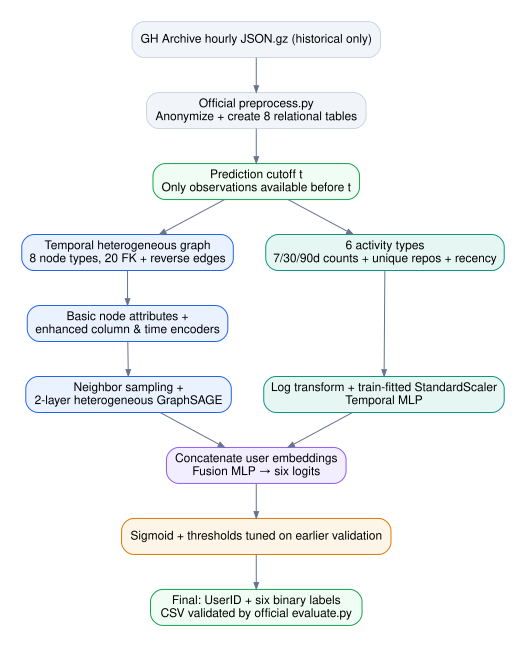

In [ ]:
def make_q4_pipeline():
    # Original first-version styling: two branches → fusion → thresholds → CSV.
    g = Digraph("pipeline", graph_attr={
        "rankdir": "TB", "pad": "0.3", "nodesep": "0.45", "ranksep": "0.48",
        "bgcolor": "white", "fontname": "Helvetica",
    }, node_attr={
        "shape": "box", "style": "rounded,filled", "fontname": "Helvetica",
        "fontsize": "12", "fillcolor": "#F8FAFC", "color": "#CBD5E1",
    }, edge_attr={"color": "#64748B", "arrowsize": "0.65"})
    g.node("raw", "GH Archive hourly JSON.gz (historical only)", fillcolor="#F1F5F9")
    g.node("prep", "Official preprocess.py\nAnonymize + create 8 relational tables", fillcolor="#F1F5F9")
    g.node("time", "Prediction cutoff t\nOnly observations available before t", fillcolor="#F0FDF4", color="#16A34A")
    g.node("graph", "Temporal heterogeneous graph\n8 node types, 20 FK + reverse edges", fillcolor="#EAF2FF", color="#2563EB")
    g.node("columns", "Basic node attributes +\nenhanced column & time encoders", fillcolor="#EAF2FF", color="#2563EB")
    g.node("sample", "Neighbor sampling +\n2-layer heterogeneous GraphSAGE", fillcolor="#EAF2FF", color="#2563EB")
    g.node("stats", "6 activity types\n7/30/90d counts + unique repos + recency", fillcolor="#E6F7F3", color="#0D9488")
    g.node("scale", "Log transform + train-fitted StandardScaler\nTemporal MLP", fillcolor="#E6F7F3", color="#0D9488")
    g.node("fusion", "Concatenate user embeddings\nFusion MLP → six logits", fillcolor="#F2EEFF", color="#8B5CF6")
    g.node("decision", "Sigmoid + thresholds tuned on earlier validation", fillcolor="#FDF6E8", color="#D97706")
    g.node("out", "Final: UserID + six binary labels\nCSV validated by official evaluate.py", fillcolor="#F0FDF4", color="#16A34A")
    for a, b in [("raw", "prep"), ("prep", "time"), ("time", "graph"),
                 ("time", "stats"), ("graph", "columns"), ("columns", "sample"),
                 ("stats", "scale"), ("sample", "fusion"), ("scale", "fusion"),
                 ("fusion", "decision"), ("decision", "out")]:
        g.edge(a, b)
    save_report_figure(g, "q4_full_pipeline")

# Run to create Q4 figure
make_q4_pipeline()

## Report checklist and interpretation

- **Q1:** Include Q1 schema graph with 8 table names and all 20 foreign keys clearly labeled, plus actual raw dataset coverage dates and counts.
- **Q2:** Explain why per-row graph nodes and both FK directions are useful, how message passing works, and what additional column encoders were used; keep the model limitations explicit.
- **Q3:** Explain cutoff conversion, availability vs actual activity timestamps, node age / cyclical time features, and 7/30/90-day user history. Mention the observed late-October missing PushEvent issue.
- **Q4:** Explain E2→E3→E3+ initialization, BCE with `pos_weight`, neighbor sampling, inference, 0.5 versus tuned thresholds, and the exact official-test output format.

**Grading:** prediction score is informational in the November revision, but reproducible code, GitHub repository, GH Archive acknowledgment, an English slide deck (maximum 16 pages), and a 16–20-minute presentation are required. Do not quote `0.5435` as the new final model score without rerunning it under matching conditions.